<a href="https://colab.research.google.com/github/abdalrahmantawfiqsultan/Duhkan_quraan/blob/main/muhammad_torchaudio8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Custom Hybrid ASR Model for سورة محمد (Surah 47) in PyTorch
## Architecture Specification:
1. **CNN Frontend:** 2 Convolutional Layers (`nn.Conv1d`)
2. **Deep BiLSTM:** 4 Bidirectional LSTM Layers (`num_layers=4, bidirectional=True`)
3. **Transformer Encoder:** 4 Layers (`nn.TransformerEncoderLayer` x 4)
4. **Transformer Decoder:** 4 Layers (`nn.TransformerDecoderLayer` x 4)
5. **Output Head:** 1 Linear Layer (`nn.Linear`) producing token logits

## Step 1 — Install Required Libraries

In [1]:
get_ipython().system(
    'pip -q install '
    '"datasets==3.3.2" '
    '"jiwer==3.0.5" '
    '"librosa>=0.10" '
    '"scipy>=1.10" '
    '"matplotlib>=3.7" pandas "arabic-reshaper>=3.0.0" "python-bidi>=0.4.2" '
    'torchaudio soundfile huggingface_hub'
)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2024.12.0 which is incompatible.


## Step 2 — Import Libraries & Configure GPU Device

In [2]:
import os
import io
import re
import math
import shutil
import random
import unicodedata
import warnings
import numpy as np
import soundfile as sf
import librosa
import jiwer

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio
import torchaudio.transforms as T
import torchaudio.functional as AF
from torch.utils.data import Dataset as TorchDataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Active Device:", device)
if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

Active Device: cuda
GPU Name: Tesla T4


## Step 3 — Mount Google Drive and Configure Project Directories (Surah Muhammad - ID: 47)

In [3]:
import glob
from datetime import datetime
from google.colab import drive

drive.mount("/content/drive")

SURAH_ID = 47
SURAH_NAME_AR = "سورة محمد"
SURAH_SLUG = "muhammad"

PROJECT_DIR = f"/content/drive/MyDrive/quran-hybrid-asr-{SURAH_SLUG}"
RAW_DIR = os.path.join(PROJECT_DIR, "raw_dataset")
CHECKPOINT_PATH = os.path.join(PROJECT_DIR, "best_hybrid_model.pt")
LOCAL_RAW_DIR = f"/content/{SURAH_SLUG}_raw_dataset"
PLOTS_DIR = os.path.join(PROJECT_DIR, "visualizations")

os.makedirs(PROJECT_DIR, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Target Surah:", SURAH_NAME_AR, f"(ID: {SURAH_ID})")

Mounted at /content/drive
Project directory: /content/drive/MyDrive/quran-hybrid-asr-muhammad
Target Surah: سورة محمد (ID: 47)


## Step 3.2 — Clean Up Old Training Artifacts in Google Drive to Start Fresh
This cell scans your project directory in Google Drive, finds older training outputs (`checkpoints*`, `final_model*`, `visualizations*`, logs, the saved `best_hybrid_model.pt`, training history and old PNG plots), sorts folders from oldest to newest, and deletes them so you can start a fresh run.
Note: `raw_dataset` is preserved so you do not need to re-download the dataset from Hugging Face.

In [4]:
# Safety Protection: Default to False to prevent accidental deletion of good checkpoints on rerun.
# Set CLEANUP_OLD_TRAINING_RUNS = True only when you explicitly desire a completely fresh run.
CLEANUP_OLD_TRAINING_RUNS = False
DELETE_ALL_TRAINING_ARTIFACTS = False  # Set to True only when intentionally wiping all previous artifacts
KEEP_NEWEST_N_FOLDERS = 3              # Keeps recent checkpoint folders intact if cleanup is enabled

if CLEANUP_OLD_TRAINING_RUNS and os.path.isdir(PROJECT_DIR):
    candidate_prefixes = ("checkpoints", "final_model", "visualizations", "logs", "runs")
    training_folders = []

    for entry in os.scandir(PROJECT_DIR):
        if entry.is_dir() and entry.name != "raw_dataset":
            if entry.name.startswith(candidate_prefixes):
                training_folders.append((entry.stat().st_mtime, entry.path, entry.name))

    training_folders.sort(key=lambda x: x[0])  # oldest -> newest

    if not training_folders:
        print("No old training folders found in Google Drive. Ready for a clean start!")
    else:
        print(f"Found {len(training_folders)} existing training folder(s) in Google Drive:")
        for mtime, path, name in training_folders:
            print(f"  - {name} (Last modified: {datetime.fromtimestamp(mtime).strftime('%Y-%m-%d %H:%M:%S')})")

        if DELETE_ALL_TRAINING_ARTIFACTS:
            folders_to_delete = training_folders
        else:
            cutoff = max(0, len(training_folders) - KEEP_NEWEST_N_FOLDERS)
            folders_to_delete = training_folders[:cutoff]

        for mtime, path, name in folders_to_delete:
            print(f"Deleting old folder: {path} ...")
            shutil.rmtree(path, ignore_errors=True)

    if DELETE_ALL_TRAINING_ARTIFACTS:
        stale_files = (
            glob.glob(os.path.join(PROJECT_DIR, "*.png"))
            + glob.glob(os.path.join(PROJECT_DIR, "*.pt"))
            + glob.glob(os.path.join(PROJECT_DIR, "training_history.json"))
            + glob.glob(os.path.join(PROJECT_DIR, "evaluation_predictions.csv"))
        )
        for fpath in stale_files:
            try:
                os.remove(fpath)
                print(f"Removed old file: {os.path.basename(fpath)}")
            except OSError:
                pass

    print("Google Drive cleanup complete! Starting fresh.")

os.makedirs(PLOTS_DIR, exist_ok=True)
print("Active Checkpoint file:", CHECKPOINT_PATH)
print("Active Visualizations directory:", PLOTS_DIR)

Active Checkpoint file: /content/drive/MyDrive/quran-hybrid-asr-muhammad/best_hybrid_model.pt
Active Visualizations directory: /content/drive/MyDrive/quran-hybrid-asr-muhammad/visualizations


## Step 3.5 — Configure Hugging Face API Token (`HF_TOKEN`)

In [5]:
from getpass import getpass
from google.colab import userdata
from huggingface_hub import login

hf_token = None

try:
    hf_token = userdata.get("HF_TOKEN")
    print("Successfully retrieved HF_TOKEN from Colab Secrets.")
except Exception:
    print("HF_TOKEN not found in Colab Secrets.")

if not hf_token:
    hf_token = getpass("Enter your Hugging Face API token (or press Enter to skip): ").strip()

if hf_token:
    os.environ["HF_TOKEN"] = hf_token
    login(token=hf_token, add_to_git_credential=False)
    print("Logged in to Hugging Face Hub successfully!")
else:
    print("Proceeding without an API token (public access mode).")

Successfully retrieved HF_TOKEN from Colab Secrets.


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Logged in to Hugging Face Hub successfully!


## Step 3.8 — Filter and Download Records for سورة محمد (Surah 47) Only

In [6]:
from huggingface_hub import HfApi
from datasets import load_dataset, load_from_disk, Audio

DATASET_ID = "Buraaq/quran-md-ayahs"

# Dictionary mapping standard reciter IDs to Arabic Reciter Names
RECITER_ARABIC_MAP = {
    "abdul_basit_murattal": "عبد الباسط عبد الصمد - مرتل",
    "abdul_basit_mujawwad": "عبد الباسط عبد الصمد - مجود",
    "abdullah_basfar": "عبد الله بصفر",
    "abdurrahmaan_as_sudais": "عبد الرحمن السديس",
    "abu_bakr_ash_shaatree": "أبو بكر الشاطري",
    "ahmed_ibn_ali_al_ajamy": "أحمد بن علي العجمي",
    "alafasy": "مشاري راشد العفاسي",
    "ali_jaber": "علي جابر",
    "ayman_suowaid": "أيمن سويد",
    "banna": "محمود علي البنا",
    "fares_abbad": "فارس عباد",
    "ghamadi": "سعد الغامدي",
    "hani_ar_rifai": "هاني الرفاعي",
    "hudhaify": "علي بن عبد الرحمن الحذيفي",
    "husary": "محمود خليل الحصري",
    "husary_muallim": "محمود خليل الحصري - معلم",
    "husary_mujawwad": "محمود خليل الحصري - مجود",
    "ibrahim_akhdar": "إبراهيم الأخضر",
    "khalefa_al_tunaiji": "خليفة الطنيجي",
    "maher_al_muaiqly": "ماهر المعيقلي",
    "minshawy_mujawwad": "محمد صديق المنشاوي - مجود",
    "minshawy_murattal": "محمد صديق المنشاوي - مرتل",
    "mohammad_al_tablaway": "محمد محمود الطبلاوي",
    "muhammad_ayyoub": "محمد أيوب",
    "muhammad_jibreel": "محمد جبريل",
    "muhsin_al_qasim": "عبد المحسن القاسم",
    "nasser_al_qatami": "ناصر القطامي",
    "salah_al_budair": "صلاح البدير",
    "salah_bukhatir": "صلاح بو خاطر",
    "saood_ash_shuraym": "سعود الشريم",
    "yasser_ad_dussary": "ياسر الدوسري",
}

def get_arabic_reciter_name(example_or_id):
    """Returns the Arabic name of the reciter from dataset metadata or mapping dictionary."""
    if isinstance(example_or_id, dict):
        if "reciter_ar" in example_or_id and example_or_id["reciter_ar"]:
            return str(example_or_id["reciter_ar"])
        rec_id = str(example_or_id.get("reciter_id", example_or_id.get("reciter_name", "")))
    else:
        rec_id = str(example_or_id)
    key = rec_id.strip().lower()
    if key in RECITER_ARABIC_MAP:
        return RECITER_ARABIC_MAP[key]
    for map_key, ar_name in RECITER_ARABIC_MAP.items():
        if map_key in key or key in map_key:
            return ar_name
    return rec_id

metadata_file = os.path.join(RAW_DIR, "dataset_info.json")

if os.path.isfile(metadata_file):
    print(f"Found cached dataset for {SURAH_NAME_AR} in Google Drive (skipping download).")
else:
    print(f"Searching Parquet files and filtering {SURAH_NAME_AR} (Surah ID: {SURAH_ID})...")
    api = HfApi()
    repo_files = api.list_repo_files(repo_id=DATASET_ID, repo_type="dataset")
    parquet_files = [
        f"hf://datasets/{DATASET_ID}/{path}"
        for path in repo_files
        if path.startswith("data/") and path.endswith(".parquet")
    ]
    print("Parquet files found:", len(parquet_files))

    filtered_ds = load_dataset(
        "parquet",
        data_files=parquet_files,
        split="train",
        filters=[("surah_id", "==", SURAH_ID)],
    )

    print("Total records downloaded:", len(filtered_ds))
    print("Unique verses:", len(set(filtered_ds["ayah_id"])))
    if "reciter_id" in filtered_ds.column_names:
        print("Unique reciters:", len(set(filtered_ds["reciter_id"])))

    os.makedirs(RAW_DIR, exist_ok=True)
    filtered_ds.save_to_disk(RAW_DIR)
    print("Saved filtered dataset to Google Drive:", RAW_DIR)

Found cached dataset for سورة محمد in Google Drive (skipping download).


## Step 3.9 — Copy Dataset to Local Colab Disk for Fast I/O

In [7]:
if not os.path.isfile(os.path.join(LOCAL_RAW_DIR, "dataset_info.json")):
    if os.path.exists(LOCAL_RAW_DIR):
        shutil.rmtree(LOCAL_RAW_DIR)
    shutil.copytree(RAW_DIR, LOCAL_RAW_DIR)

raw_dataset = load_from_disk(LOCAL_RAW_DIR)
TOTAL_SURAH_VERSES = len(set(raw_dataset["ayah_id"]))
print("Local dataset ready:", len(raw_dataset), "records")
print("Total unique verses in Surah:", TOTAL_SURAH_VERSES)
print("Dataset columns:", raw_dataset.column_names)

# Build a lookup table from reciter_id to Arabic reciter name using dataset columns if available
reciter_col = "reciter_id" if "reciter_id" in raw_dataset.column_names else "reciter_name"
if "reciter_ar" in raw_dataset.column_names:
    for r_id, r_ar in zip(raw_dataset[reciter_col], raw_dataset["reciter_ar"]):
        if r_id and r_ar:
            RECITER_ARABIC_MAP[str(r_id).strip().lower()] = str(r_ar)

Local dataset ready: 1140 records
Total unique verses in Surah: 38
Dataset columns: ['surah_id', 'ayah_id', 'surah_name_ar', 'surah_name_en', 'surah_name_tr', 'ayah_count', 'ayah_ar', 'ayah_en', 'ayah_tr', 'reciter_id', 'reciter_name', 'audio']


## Step 4 — Split Dataset by Reciters (80% Train / 10% Val / 10% Test) & Validate Audio
Whole reciters are held out, so validation and test measure generalization to **unseen voices**:
- **80%** of reciters -> Training
- **10%** of reciters -> Evaluation / Validation during training
- **10%** of reciters -> Final Testing

In [8]:
all_reciters = sorted(set(raw_dataset[reciter_col]))

rng = random.Random(SEED)
rng.shuffle(all_reciters)

n_eval = max(1, round(len(all_reciters) * 0.10))
n_test = max(1, round(len(all_reciters) * 0.10))

eval_reciters = set(all_reciters[:n_eval])
test_reciters = set(all_reciters[n_eval : n_eval + n_test])
train_reciters = set(all_reciters[n_eval + n_test :])

reciter_column = raw_dataset[reciter_col]
n_train_rec = sum(r in train_reciters for r in reciter_column)
n_eval_rec = sum(r in eval_reciters for r in reciter_column)
n_test_rec = sum(r in test_reciters for r in reciter_column)

print(f"Surah: {SURAH_NAME_AR}")
print(f"Total Reciters: {len(all_reciters)}")
print(f"Training Reciters (80%):   {len(train_reciters)} reciters -> {n_train_rec} audio records")
print(f"Evaluation Reciters (10%): {len(eval_reciters)} reciters -> {n_eval_rec} audio records")
print(f"Testing Reciters (10%):    {len(test_reciters)} reciters -> {n_test_rec} audio records")

print("\nHeld-out Evaluation Reciters (10% - Arabic):")
for r_id in sorted(eval_reciters):
    print(f"  - {get_arabic_reciter_name(r_id)} ({r_id})")

print("\nHeld-out Testing Reciters (10% - Arabic):")
for r_id in sorted(test_reciters):
    print(f"  - {get_arabic_reciter_name(r_id)} ({r_id})")

print("\nTraining Reciters (80% - Arabic):")
for r_id in sorted(train_reciters):
    print(f"  - {get_arabic_reciter_name(r_id)}")

raw_dataset_no_decode = raw_dataset.cast_column("audio", Audio(sampling_rate=16000, decode=False))

def filter_valid_split(ds, target_reciter_set):
    indices = [i for i, r in enumerate(ds[reciter_col]) if r in target_reciter_set]
    sub_ds = ds.select(indices)

    def is_valid(example):
        try:
            audio_dict = example["audio"]
            if not audio_dict or "bytes" not in audio_dict or audio_dict["bytes"] is None:
                return False
            with io.BytesIO(audio_dict["bytes"]) as f:
                arr, sr = sf.read(f)
            if arr.ndim > 1:
                arr = arr.mean(axis=-1)
            dur = len(arr) / sr
            return 0.4 <= dur <= 30.0 and np.isfinite(arr).all() and np.max(np.abs(arr)) > 1e-4
        except Exception:
            return False

    sub_ds = sub_ds.filter(is_valid, desc="Validating audio")
    return sub_ds.cast_column("audio", Audio(sampling_rate=16000, decode=True))

train_audio = filter_valid_split(raw_dataset_no_decode, train_reciters)
eval_audio = filter_valid_split(raw_dataset_no_decode, eval_reciters)
test_audio = filter_valid_split(raw_dataset_no_decode, test_reciters)

print(f"Train clips (80%): {len(train_audio)} | Val clips (10%): {len(eval_audio)} | Test clips (10%): {len(test_audio)}")

Surah: سورة محمد
Total Reciters: 30
Training Reciters (80%):   24 reciters -> 912 audio records
Evaluation Reciters (10%): 3 reciters -> 114 audio records
Testing Reciters (10%):    3 reciters -> 114 audio records

Held-out Evaluation Reciters (10% - Arabic):
  - فارس عباد (fares_abbad)
  - محمود خليل الحصري (husary)
  - محمد صديق المنشاوي - مرتل (minshawy_murattal)

Held-out Testing Reciters (10% - Arabic):
  - مشاري راشد العفاسي (alafasy)
  - محمد جبريل (muhammad_jibreel)
  - خليفة الطنيجي (tunaiji)

Training Reciters (80% - Arabic):
  - عبد الباسط عبد الصمد - مرتل
  - abdullaah_3awwaad_al_juhaynee
  - عبد الله بصفر
  - abdulsamad
  - عبد الرحمن السديس
  - أبو بكر الشاطري
  - علي جابر
  - ayman_sowaid
  - محمود علي البنا
  - سعد الغامدي
  - hani_rifai
  - علي بن عبد الرحمن الحذيفي
  - محمود خليل الحصري - مجود
  - hussary.teacher
  - إبراهيم الأخضر
  - محمد صديق المنشاوي - مجود
  - minshawy_teacher
  - mostafa_ismail
  - عبد المحسن القاسم
  - nasser_alqatami
  - سعود الشريم
  - محمود 

Validating audio:   0%|          | 0/912 [00:00<?, ? examples/s]

Validating audio:   0%|          | 0/114 [00:00<?, ? examples/s]

Validating audio:   0%|          | 0/114 [00:00<?, ? examples/s]

Train clips (80%): 692 | Val clips (10%): 95 | Test clips (10%): 99


## Step 5 — Build Arabic Character & Diacritic Tokenizer + Log-Mel Feature Extractor

In [9]:
SR = 16000
N_MELS = 80

def preprocess_quran_text(text):
    if not text:
        return ""
    text = unicodedata.normalize("NFC", str(text))
    text = re.sub(r"[\u200B-\u200F\u202A-\u202E\uFEFF\u06DE\u06E9]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def normalize_arabic(text):
    text = unicodedata.normalize("NFC", text)
    text = re.sub(r"[\u064B-\u065F\u0670\u0640\u06D6-\u06ED]", "", text)
    text = re.sub(r"[إأآٱ]", "ا", text)
    text = text.replace("ى", "ي")
    text = re.sub(r"[^\w\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

class QuranCharTokenizer:
    """Character-level Arabic + Diacritics tokenizer for custom Seq2Seq decoding."""
    def __init__(self, texts):
        self.pad_token = "<pad>"
        self.sos_token = "<sos>"
        self.eos_token = "<eos>"
        self.unk_token = "<unk>"

        specials = [self.pad_token, self.sos_token, self.eos_token, self.unk_token]
        unique_chars = sorted(set("".join(preprocess_quran_text(t) for t in texts)))
        self.vocab = specials + unique_chars

        self.char2id = {ch: idx for idx, ch in enumerate(self.vocab)}
        self.id2char = {idx: ch for idx, ch in enumerate(self.vocab)}

        self.pad_id = self.char2id[self.pad_token]
        self.sos_id = self.char2id[self.sos_token]
        self.eos_id = self.char2id[self.eos_token]
        self.unk_id = self.char2id[self.unk_token]

    def __len__(self):
        return len(self.vocab)

    def encode(self, text):
        clean = preprocess_quran_text(text)
        ids = [self.sos_id] + [self.char2id.get(ch, self.unk_id) for ch in clean] + [self.eos_id]
        return ids

    def decode(self, token_ids):
        chars = []
        for idx in token_ids:
            idx = int(idx)
            if idx == self.eos_id:
                break
            if idx in (self.pad_id, self.sos_id, self.unk_id):
                continue
            chars.append(self.id2char.get(idx, ""))
        return "".join(chars).strip()

tokenizer = QuranCharTokenizer(raw_dataset["ayah_ar"])
print("Vocabulary Size (Arabic letters + Tashkeel + Specials):", len(tokenizer))

# ---------------------------------------------------------------------------
# Native torchaudio feature transforms
# ---------------------------------------------------------------------------
mel_spectrogram_transform = T.MelSpectrogram(
    sample_rate=SR,
    n_fft=400,
    win_length=400,
    hop_length=160,
    n_mels=N_MELS,
    power=2.0,
)
amplitude_to_db_transform = T.AmplitudeToDB(stype="power", top_db=80.0)

# SpecAugment (applied on the spectrogram; multiple masks for stronger regularization)
time_mask_transform = T.TimeMasking(time_mask_param=20)
freq_mask_transform = T.FrequencyMasking(freq_mask_param=8)

MAX_SAMPLES = 30 * SR

# ---------------------------------------------------------------------------
# Deterministic preprocessing (train / val / test) — torchaudio only
# ---------------------------------------------------------------------------
def trim_silence_torch(wav, sr=SR, top_db=35.0, margin_sec=0.10, frame_len=400, hop=160):
    """Energy-based leading/trailing silence trimming with a natural breath margin."""
    if wav.numel() < frame_len * 2:
        return wav
    frames = wav.unfold(0, frame_len, hop)
    rms = frames.pow(2).mean(dim=1).sqrt() + 1e-9
    db = 20.0 * torch.log10(rms / rms.max())
    voiced = torch.nonzero(db > -top_db).flatten()
    if voiced.numel() == 0:
        return wav
    margin = int(margin_sec * sr)
    start = max(0, int(voiced[0]) * hop - margin)
    end = min(wav.numel(), int(voiced[-1]) * hop + frame_len + margin)
    return wav[start:end]


def preprocess_waveform(audio_array, sr=SR):
    """
    1. Mono + NaN/Inf sanitization + DC-offset removal
    2. Band-pass (65 Hz high-pass + 7600 Hz low-pass biquads)
    3. Pre-emphasis blend (consonant clarity) via AF.preemphasis
    4. Silence trimming with 100 ms margin
    5. 15 ms fade-in/out (T.Fade) to avoid boundary clicks
    6. Peak normalization to 0.95, hard cap at 30 s
    """
    y = np.nan_to_num(np.asarray(audio_array, dtype=np.float32), nan=0.0, posinf=0.0, neginf=0.0)
    if y.ndim > 1:
        y = y.mean(axis=-1)
    wav = torch.from_numpy(y).float()
    if wav.numel() == 0:
        return torch.zeros(int(0.5 * sr))
    wav = wav - wav.mean()

    if wav.numel() > 64:
        wav = AF.highpass_biquad(wav, sr, cutoff_freq=65.0)
        wav = AF.lowpass_biquad(wav, sr, cutoff_freq=7600.0)

    wav = 0.85 * wav + 0.15 * AF.preemphasis(wav.unsqueeze(0), coeff=0.97).squeeze(0)

    wav = trim_silence_torch(wav, sr)

    fade = int(0.015 * sr)
    if wav.numel() > 4 * fade:
        wav = T.Fade(fade_in_len=fade, fade_out_len=fade, fade_shape="half_sine")(wav)

    peak = wav.abs().max()
    if peak > 1e-6:
        wav = wav / peak * 0.95
    return wav[:MAX_SAMPLES]


# ---------------------------------------------------------------------------
# Stochastic waveform augmentation (train only) — torchaudio only
# ---------------------------------------------------------------------------
def augment_waveform_torch(wav, sr=SR):
    """
    Random chain of: speed perturbation (resample), pitch shift, synthetic room/mosque reverb
    (FFT convolution), white/pink noise at random SNR (AF.add_noise), temporal shift,
    and random gain (T.Vol).
    """
    # 1. Speed perturbation (changes tempo + pitch, like Kaldi speed perturb): 0.9x - 1.1x
    if random.random() < 0.5:
        factor = random.choice([0.9, 0.95, 1.05, 1.1])
        wav = AF.resample(wav, orig_freq=int(sr * factor), new_freq=sr)

    # 2. Pitch shift +/-1.5 semitones (simulates different reciter registers)
    if random.random() < 0.25 and wav.numel() > sr // 4:
        n_steps = random.uniform(-1.5, 1.5)
        wav = AF.pitch_shift(wav, sr, n_steps)

    # 3. Synthetic room / mosque reverb via exponentially decaying noise impulse response
    if random.random() < 0.35:
        ir_len = int(random.uniform(0.08, 0.30) * sr)
        t = torch.linspace(0.0, 1.0, ir_len)
        ir = torch.randn(ir_len) * torch.exp(-random.uniform(5.0, 9.0) * t)
        ir[0] = 1.0
        ir = ir / ir.norm()
        wet = random.uniform(0.10, 0.30)
        reverb = AF.fftconvolve(wav, ir)[: wav.numel()]
        wav = (1 - wet) * wav + wet * reverb

    # 4. Ambient noise (white or pink) at SNR 15-35 dB
    if random.random() < 0.5 and wav.numel() > 32:
        white = torch.randn(wav.numel())
        if random.random() < 0.5:  # pink (1/f) noise via frequency-domain shaping
            spec = torch.fft.rfft(white)
            freqs = torch.fft.rfftfreq(wav.numel())
            freqs[0] = 1.0
            noise = torch.fft.irfft(spec / freqs.sqrt(), n=wav.numel())
        else:
            noise = white
        snr = torch.tensor([random.uniform(15.0, 35.0)])
        wav = AF.add_noise(wav.unsqueeze(0), noise.unsqueeze(0), snr).squeeze(0)

    # 5. Random temporal shift (pad silence front/back)
    if random.random() < 0.4:
        front = int(random.uniform(0.0, 0.20) * sr)
        back = int(random.uniform(0.0, 0.20) * sr)
        wav = F.pad(wav, (front, back))

    # 6. Random gain -6 dB .. +3 dB, then re-limit
    if random.random() < 0.5:
        wav = T.Vol(gain=random.uniform(-6.0, 3.0), gain_type="db")(wav)
    peak = wav.abs().max()
    if peak > 1.0:
        wav = wav / peak * 0.95
    return wav[:MAX_SAMPLES]


# Fast waveform augmentation for training (excludes slow CPU pitch_shift)
def augment_waveform_fast(wav, sr=SR):
    """
    Lightweight, vectorized torchaudio augmentation: speed perturbation via resample,
    impulse response reverb, pink/white noise, temporal shift, and gain.
    """
    # 1. Fast speed perturbation (changes tempo and pitch simultaneously): 0.92x - 1.08x
    if random.random() < 0.45:
        factor = random.choice([0.92, 0.96, 1.04, 1.08])
        wav = AF.resample(wav, orig_freq=int(sr * factor), new_freq=sr)

    # 2. Fast Synthetic Room/Mosque Reverb
    if random.random() < 0.30:
        ir_len = int(random.uniform(0.06, 0.20) * sr)
        t = torch.linspace(0.0, 1.0, ir_len)
        ir = torch.randn(ir_len) * torch.exp(-7.0 * t)
        ir[0] = 1.0
        ir = ir / (ir.norm() + 1e-8)
        wet = random.uniform(0.08, 0.22)
        reverb = AF.fftconvolve(wav, ir)[: wav.numel()]
        wav = (1.0 - wet) * wav + wet * reverb

    # 3. Fast ambient noise injection (White / Pink) at SNR 18-35 dB
    if random.random() < 0.45 and wav.numel() > 32:
        white = torch.randn(wav.numel())
        if random.random() < 0.5:
            spec = torch.fft.rfft(white)
            freqs = torch.fft.rfftfreq(wav.numel())
            freqs[0] = 1.0
            noise = torch.fft.irfft(spec / freqs.sqrt(), n=wav.numel())
        else:
            noise = white
        snr = torch.tensor([random.uniform(18.0, 35.0)])
        wav = AF.add_noise(wav.unsqueeze(0), noise.unsqueeze(0), snr).squeeze(0)

    # 4. Random temporal shift & padding
    if random.random() < 0.35:
        front = int(random.uniform(0.0, 0.15) * sr)
        back = int(random.uniform(0.0, 0.15) * sr)
        wav = F.pad(wav, (front, back))

    # 5. Random gain
    if random.random() < 0.45:
        wav = T.Vol(gain=random.uniform(-5.0, 2.5), gain_type="db")(wav)

    peak = wav.abs().max()
    if peak > 1.0:
        wav = wav / peak * 0.95
    return wav[:MAX_SAMPLES]


def extract_log_mel_from_waveform(waveform, augment=False):
    """Extracts normalized Log-Mel spectrogram directly from an in-memory waveform tensor."""
    if not isinstance(waveform, torch.Tensor):
        waveform = torch.from_numpy(waveform).float()
    if waveform.ndim == 1:
        waveform = waveform.unsqueeze(0)

    mel_spec = mel_spectrogram_transform(waveform)
    log_mel = amplitude_to_db_transform(mel_spec)
    log_mel = (log_mel - log_mel.mean()) / (log_mel.std() + 1e-6)

    # SpecAugment: 2 time masks + 2 frequency masks
    if augment and log_mel.size(-1) > 30:
        for _ in range(2):
            log_mel = time_mask_transform(log_mel)
            log_mel = freq_mask_transform(log_mel)

    return log_mel.squeeze(0).transpose(0, 1).contiguous()


def extract_log_mel(audio_array, sr=SR, n_mels=N_MELS, augment=False):
    """
    Full torchaudio pipeline: preprocess -> (optional waveform augmentation) -> Log-Mel ->
    instance normalization -> (optional SpecAugment). Returns (Time, N_MELS).
    """
    waveform = preprocess_waveform(audio_array, sr)
    if augment:
        waveform = augment_waveform_torch(waveform, sr)
    return extract_log_mel_from_waveform(waveform, augment=augment)

Vocabulary Size (Arabic letters + Tashkeel + Specials): 54


## Step 6 — Define the Custom Hybrid PyTorch Architecture
Exactly matches your specification:
- **CNN:** 2 Convolutional layers (`Conv1d` + `BatchNorm1d` + `GELU`)
- **Deep BiLSTM:** 4 Bidirectional LSTM layers (`num_layers=4, bidirectional=True`)
- **Transformer Encoder:** 4 layers (`num_layers=4`)
- **Transformer Decoder:** 4 layers (`num_layers=4`)
- **Output Head:** 1 Linear layer (`nn.Linear(d_model, vocab_size)`)

In [10]:
class PositionalEncoding(nn.Module):
    """Standard sinusoidal positional encoding for Transformer Encoder & Decoder."""
    def __init__(self, d_model, max_len=4000, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))  # Shape: (1, max_len, d_model)

    def forward(self, x):
        x = x + self.pe[:, : x.size(1), :]
        return self.dropout(x)


class HybridCNNBiLSTMTransformerASR(nn.Module):
    """
    Hybrid Speech Recognition Architecture for Quranic Recitation:
      1. CNN Frontend: 2 Convolutional Layers
      2. Deep BiLSTM: 4 Bidirectional Layers
      3. Transformer Encoder: 4 Layers
      4. Transformer Decoder: 4 Layers
      5. Output Head: 1 Linear Layer producing token probabilities/logits
    """
    def __init__(
        self,
        n_mels: int = 80,
        vocab_size: int = 100,
        d_model: int = 256,
        nhead: int = 8,
        dim_feedforward: int = 1024,
        dropout: float = 0.15,
        pad_id: int = 0,
    ):
        super().__init__()
        self.d_model = d_model
        self.pad_id = pad_id

        # =====================================================================
        # 1. CNN Frontend: Exactly 2 Convolutional Layers
        #    Downsamples time frames by 4x (stride=2 in Conv1, stride=2 in Conv2)
        #    Uses LayerNorm per frame to ensure padding zero-frames never pollute batch statistics
        # =====================================================================
        self.conv1 = nn.Conv1d(
            in_channels=n_mels,
            out_channels=d_model,
            kernel_size=3,
            stride=2,
            padding=1,
        )
        self.ln1 = nn.LayerNorm(d_model)

        self.conv2 = nn.Conv1d(
            in_channels=d_model,
            out_channels=d_model,
            kernel_size=3,
            stride=2,
            padding=1,
        )
        self.ln2 = nn.LayerNorm(d_model)
        self.cnn_dropout = nn.Dropout(dropout)

        # =====================================================================
        # 2. Deep BiLSTM: Exactly 4 Bidirectional Layers
        #    Pre-Norm + Orthogonal Recurrent Init + Forget Gate Bias = 1.0 + Learnable Residual Gate
        # =====================================================================
        assert d_model % 2 == 0, "d_model must be divisible by 2 for bidirectional LSTM."
        self.bilstm_pre_norm = nn.LayerNorm(d_model)
        self.deep_bilstm = nn.LSTM(
            input_size=d_model,
            hidden_size=d_model // 2,
            num_layers=4,
            batch_first=True,
            bidirectional=True,
            dropout=dropout,
        )
        self.bilstm_gate = nn.Parameter(torch.tensor(0.15))
        self.bilstm_norm = nn.LayerNorm(d_model)

        self._init_bilstm_weights()

        # =====================================================================
        # 3. Transformer Encoder: Exactly 4 Layers
        # =====================================================================
        self.pos_encoder = PositionalEncoding(d_model, max_len=4000, dropout=dropout)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.transformer_encoder = nn.TransformerEncoder(
            encoder_layer=encoder_layer,
            num_layers=4,
            norm=nn.LayerNorm(d_model),
        )

        # =====================================================================
        # 4. Transformer Decoder: Exactly 4 Layers
        # =====================================================================
        self.token_embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        self.pos_decoder = PositionalEncoding(d_model, max_len=1024, dropout=dropout)
        decoder_layer = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.transformer_decoder = nn.TransformerDecoder(
            decoder_layer=decoder_layer,
            num_layers=4,
            norm=nn.LayerNorm(d_model),
        )

        # =====================================================================
        # 5. Output Heads:
        #    - Primary Attention-Decoder Head: 1 Linear Layer for Token Logits
        #    - Auxiliary CTC Head: 1 Linear Layer on Encoder Memory (Hybrid CTC/Attention)
        # =====================================================================
        self.output_head = nn.Linear(d_model, vocab_size)
        self.ctc_head = nn.Linear(d_model, vocab_size)

    def _init_bilstm_weights(self):
        """Orthogonal initialization for recurrent weights and forget-gate bias = 1.0 to prevent gradient vanishing."""
        for name, param in self.deep_bilstm.named_parameters():
            if "weight_ih" in name:
                nn.init.xavier_uniform_(param.data)
            elif "weight_hh" in name:
                nn.init.orthogonal_(param.data)
            elif "bias" in name:
                param.data.fill_(0.0)
                # Set forget gate bias to 1.0 (PyTorch LSTM bias format: [i, f, g, o])
                n = param.size(0)
                param.data[n // 4 : n // 2].fill_(1.0)

    def _compute_cnn_lengths(self, input_lengths: torch.Tensor) -> torch.Tensor:
        """Computes valid sequence lengths after the two stride-2 Conv1d layers."""
        lengths = torch.div(input_lengths + 2 * 1 - 3, 2, rounding_mode="floor") + 1
        lengths = torch.div(lengths + 2 * 1 - 3, 2, rounding_mode="floor") + 1
        return torch.clamp(lengths, min=1)

    def encode_audio(self, mel_features: torch.Tensor, mel_lengths: torch.Tensor):
        """
        Passes audio features through:
          2-Layer CNN (with per-frame LayerNorm) -> 4-Layer Deep BiLSTM (with packed sequences & learnable gate) -> 4-Layer Transformer Encoder
        """
        # mel_features shape: (Batch, Time, n_mels) -> transpose to (Batch, n_mels, Time) for Conv1d
        x = mel_features.transpose(1, 2)

        # 1. 2-Layer CNN Frontend (with per-frame LayerNorm to protect statistics from padding contamination)
        x = self.conv1(x).transpose(1, 2)       # (Batch, Time1, d_model)
        x = F.gelu(self.ln1(x)).transpose(1, 2) # back to (Batch, d_model, Time1)
        x = self.conv2(x).transpose(1, 2)       # (Batch, Time2, d_model)
        x = F.gelu(self.ln2(x))                 # (Batch, Time2, d_model)
        x = self.cnn_dropout(x)

        enc_lengths = self._compute_cnn_lengths(mel_lengths)

        # 2. 4-Layer Deep BiLSTM with sequence packing and learnable residual gating
        total_len = x.size(1)
        bilstm_in = self.bilstm_pre_norm(x)
        packed_x = pack_padded_sequence(
            bilstm_in, enc_lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        packed_out, _ = self.deep_bilstm(packed_x)
        unpacked_out, _ = pad_packed_sequence(
            packed_out, batch_first=True, total_length=total_len
        )
        # Learnable residual gate permits immediate CNN gradient propagation into Transformer Encoder
        x = self.bilstm_norm(x + self.bilstm_gate * unpacked_out)

        # Build padding mask for Transformer Encoder: True indicates padded positions
        max_enc_len = x.size(1)
        src_key_padding_mask = (
            torch.arange(max_enc_len, device=x.device).unsqueeze(0) >= enc_lengths.unsqueeze(1)
        )

        # 3. 4-Layer Transformer Encoder
        x = self.pos_encoder(x)
        memory = self.transformer_encoder(
            src=x,
            src_key_padding_mask=src_key_padding_mask,
        )
        return memory, src_key_padding_mask

    def forward(
        self,
        mel_features: torch.Tensor,
        mel_lengths: torch.Tensor,
        tgt_input_ids: torch.Tensor,
        return_ctc: bool = False,
    ):
        """
        Forward pass for training with teacher forcing.
        If return_ctc=True, returns (decoder_logits, ctc_logits, enc_lengths).
        Otherwise returns decoder_logits of shape (Batch, Target_Len, Vocab_Size).
        """
        memory, memory_key_padding_mask = self.encode_audio(mel_features, mel_lengths)

        # Prepare target embeddings and masks for 4-Layer Transformer Decoder
        tgt_seq_len = tgt_input_ids.size(1)
        tgt_causal_mask = nn.Transformer.generate_square_subsequent_mask(
            tgt_seq_len, device=tgt_input_ids.device
        )
        tgt_key_padding_mask = (tgt_input_ids == self.pad_id)

        tgt_emb = self.token_embedding(tgt_input_ids) * math.sqrt(self.d_model)
        tgt_emb = self.pos_decoder(tgt_emb)

        # 4. 4-Layer Transformer Decoder
        decoder_out = self.transformer_decoder(
            tgt=tgt_emb,
            memory=memory,
            tgt_mask=tgt_causal_mask,
            tgt_key_padding_mask=tgt_key_padding_mask,
            memory_key_padding_mask=memory_key_padding_mask,
        )

        # 5. Output Heads
        logits = self.output_head(decoder_out)
        if return_ctc:
            ctc_logits = self.ctc_head(memory)
            enc_lengths = self._compute_cnn_lengths(mel_lengths)
            return logits, ctc_logits, enc_lengths
        return logits

    @torch.no_grad()
    def greedy_decode(
        self,
        mel_features: torch.Tensor,
        mel_lengths: torch.Tensor,
        sos_id: int,
        eos_id: int,
        max_len: int = 300,
        no_repeat_ngram_size: int = 4,
        repetition_penalty: float = 1.45,
    ):
        """
        Anti-Repetition Hybrid Decoding:
          1. Hard N-Gram Banning: Masks tokens to -inf if they form an already generated 4-gram.
          2. Realistic Recitation Rate Cap: enc_lens * 0.38 + 12 (~9.5 chars/sec max, preventing spurious insertions).
          3. Fast Tail-Loop Breaker: Detects degenerate tail loops (<=3 unique tokens in last 12 chars) or trigram collapse (<0.45)
             and safely falls back to monotonic CTC hypothesis.
        """
        self.eval()
        with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
            memory, memory_key_padding_mask = self.encode_audio(mel_features, mel_lengths)
            ctc_logits = self.ctc_head(memory)
            batch_size = mel_features.size(0)

            # 1. Monotonic CTC greedy baseline per batch item
            ctc_tokens = torch.argmax(ctc_logits, dim=-1)  # (Batch, Time)
            ctc_fallbacks = []
            for b in range(batch_size):
                collapsed = []
                prev = -1
                for tok in ctc_tokens[b].tolist():
                    if tok != prev:
                        if tok not in (self.pad_id, sos_id, eos_id):
                            collapsed.append(tok)
                        prev = tok
                ctc_fallbacks.append(collapsed)

            # 2. Strict physical recitation rate limit (25 fps / ~8-9 chars/sec max)
            enc_lens = self._compute_cnn_lengths(mel_lengths)
            max_dynamic = min(max_len, int(enc_lens.max().item() * 0.38) + 14)

            generated = torch.full((batch_size, 1), sos_id, dtype=torch.long, device=mel_features.device)
            finished = torch.zeros(batch_size, dtype=torch.bool, device=mel_features.device)

            for step in range(max_dynamic):
                tgt_seq_len = generated.size(1)
                tgt_causal_mask = nn.Transformer.generate_square_subsequent_mask(
                    tgt_seq_len, device=generated.device
                )
                tgt_emb = self.token_embedding(generated) * math.sqrt(self.d_model)
                tgt_emb = self.pos_decoder(tgt_emb)

                dec_out = self.transformer_decoder(
                    tgt=tgt_emb,
                    memory=memory,
                    tgt_mask=tgt_causal_mask,
                    memory_key_padding_mask=memory_key_padding_mask,
                )
                logits = self.output_head(dec_out[:, -1, :])

                # 3. Hard No-Repeat N-Gram Banning
                if no_repeat_ngram_size > 0 and generated.size(1) >= no_repeat_ngram_size:
                    for b in range(batch_size):
                        gen_list = generated[b].tolist()
                        cur_prefix = tuple(gen_list[-(no_repeat_ngram_size - 1) :])
                        banned_tokens = set()
                        for i in range(len(gen_list) - no_repeat_ngram_size + 1):
                            if tuple(gen_list[i : i + no_repeat_ngram_size - 1]) == cur_prefix:
                                banned_tokens.add(gen_list[i + no_repeat_ngram_size - 1])
                        for banned_tok in banned_tokens:
                            if banned_tok not in (sos_id, eos_id, self.pad_id):
                                logits[b, banned_tok] = -float("inf")

                # 4. Soft repetition penalty on recent tokens
                if repetition_penalty > 1.0 and generated.size(1) > 1:
                    recent = generated[:, max(1, generated.size(1) - 5) :]
                    for b in range(batch_size):
                        for tok in set(recent[b].tolist()):
                            if tok not in (eos_id, self.pad_id):
                                if logits[b, tok] > 0:
                                    logits[b, tok] /= repetition_penalty
                                else:
                                    logits[b, tok] *= repetition_penalty

                next_tokens = torch.argmax(logits, dim=-1, keepdim=True)

                # Individual per-audio clip duration cap
                for b in range(batch_size):
                    ind_limit = int(enc_lens[b].item() * 0.38) + 12
                    if step >= ind_limit:
                        finished[b] = True

                generated = torch.cat([generated, next_tokens], dim=1)
                finished = finished | (next_tokens.squeeze(1) == eos_id)
                if finished.all():
                    break

            # 5. Sensitive Tail-Loop & Collapse Detector
            final_sequences = []
            for b in range(batch_size):
                seq = generated[b].tolist()
                has_loop = False

                # Check A: Tail loop (if last 12 chars repeat only 1-3 distinct tokens)
                if len(seq) > 12:
                    tail = seq[-12:]
                    if len(set(tail)) <= 3:
                        has_loop = True

                # Check B: Trigram diversity collapse
                if not has_loop and len(seq) > 20:
                    trigrams = [tuple(seq[i : i + 3]) for i in range(len(seq) - 2)]
                    unique_ratio = len(set(trigrams)) / max(1, len(trigrams))
                    if unique_ratio < 0.45:
                        has_loop = True

                # Trigger CTC fallback if loop occurred and CTC prediction is valid
                if has_loop and len(ctc_fallbacks[b]) > 3:
                    fb_seq = [sos_id] + ctc_fallbacks[b] + [eos_id]
                    final_sequences.append(torch.tensor(fb_seq, device=mel_features.device))
                else:
                    final_sequences.append(torch.tensor(seq, device=mel_features.device))

            padded_out = nn.utils.rnn.pad_sequence(final_sequences, batch_first=True, padding_value=self.pad_id)
            return padded_out

    @torch.no_grad()
    def ctc_prefix_beam_search(
        self,
        ctc_log_probs: torch.Tensor,
        beam_size: int = 10,
        blank_id: int = 0,
    ):
        """
        Fast CTC Prefix Beam Search on a single clip's (T, Vocab) log-probabilities.
        Returns list of (token_list, ctc_log_prob) sorted descending.
        """
        T, V = ctc_log_probs.shape
        ctc_probs = torch.exp(ctc_log_probs)
        beams = {(): (1.0, 0.0)}

        for t in range(T):
            probs_t = ctc_probs[t]
            top_k = min(15, V)
            _, top_indices = torch.topk(probs_t, top_k)
            candidate_tokens = set(top_indices.tolist())
            candidate_tokens.add(blank_id)

            next_beams = {}
            for prefix, (p_b, p_nb) in beams.items():
                p_total = p_b + p_nb
                if p_total <= 0.0:
                    continue

                for c in candidate_tokens:
                    p_c = float(probs_t[c])
                    if p_c <= 1e-8:
                        continue

                    if c == blank_id:
                        if prefix not in next_beams:
                            next_beams[prefix] = [0.0, 0.0]
                        next_beams[prefix][0] += p_total * p_c
                    else:
                        new_prefix = prefix + (c,)
                        if len(prefix) > 0 and prefix[-1] == c:
                            if prefix not in next_beams:
                                next_beams[prefix] = [0.0, 0.0]
                            next_beams[prefix][1] += p_nb * p_c
                            if new_prefix not in next_beams:
                                next_beams[new_prefix] = [0.0, 0.0]
                            next_beams[new_prefix][1] += p_b * p_c
                        else:
                            if new_prefix not in next_beams:
                                next_beams[new_prefix] = [0.0, 0.0]
                            next_beams[new_prefix][1] += p_total * p_c

            beams = dict(
                sorted(
                    next_beams.items(),
                    key=lambda item: item[1][0] + item[1][1],
                    reverse=True,
                )[:beam_size]
            )

        results = []
        for prefix, (p_b, p_nb) in beams.items():
            tot = max(p_b + p_nb, 1e-12)
            results.append((list(prefix), math.log(tot)))
        results.sort(key=lambda x: x[1], reverse=True)
        return results

    @torch.no_grad()
    def joint_ctc_attention_decode(
        self,
        mel_features: torch.Tensor,
        mel_lengths: torch.Tensor,
        sos_id: int,
        eos_id: int,
        beam_size: int = 10,
        ctc_weight: float = 0.65,
        length_penalty: float = 0.1,
    ):
        """
        Joint CTC/Attention Beam Search Decoding:
          1. Generates top-B candidate character sequences via CTC Prefix Beam Search.
          2. Guaranteed inclusion of the greedy CTC hypothesis.
          3. Evaluates parallel cross-attention Transformer Decoder log-probabilities for all candidates in one batched forward pass.
          4. Ranks hypotheses using: Score = ctc_weight * Score_ctc + (1 - ctc_weight) * Score_att + length_penalty * Length.
        """
        self.eval()
        with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
            memory, memory_key_padding_mask = self.encode_audio(mel_features, mel_lengths)
            ctc_logits = self.ctc_head(memory)
            enc_lengths = self._compute_cnn_lengths(mel_lengths)
            batch_size = mel_features.size(0)

            best_sequences = []
            for b in range(batch_size):
                cur_len = enc_lengths[b].item()
                clip_memory = memory[b : b + 1, :cur_len, :]
                clip_ctc_logits = ctc_logits[b, :cur_len, :]
                clip_log_probs = F.log_softmax(clip_ctc_logits.float(), dim=-1)

                # 1. Greedy CTC baseline (guaranteed candidate)
                greedy_toks = torch.argmax(clip_ctc_logits, dim=-1).tolist()
                collapsed = []
                prev = -1
                for tok in greedy_toks:
                    if tok != prev:
                        if tok not in (self.pad_id, sos_id, eos_id):
                            collapsed.append(tok)
                        prev = tok

                # 2. CTC Prefix Beam Search
                beam_hyps = self.ctc_prefix_beam_search(
                    clip_log_probs, beam_size=beam_size, blank_id=self.pad_id
                )

                candidate_map = {}
                if collapsed:
                    candidate_map[tuple(collapsed)] = 0.0  # greedy baseline
                for hyp_tokens, ctc_score in beam_hyps:
                    if hyp_tokens:
                        candidate_map[tuple(hyp_tokens)] = ctc_score

                if not candidate_map:
                    best_sequences.append(torch.tensor([sos_id, eos_id], device=mel_features.device))
                    continue

                candidates = list(candidate_map.keys())
                ctc_scores = [candidate_map[k] for k in candidates]
                K = len(candidates)

                # 3. Parallel Attention Rescoring through Transformer Decoder
                tgt_inputs = [
                    torch.tensor([sos_id] + list(c), dtype=torch.long, device=mel_features.device)
                    for c in candidates
                ]
                padded_tgt = nn.utils.rnn.pad_sequence(tgt_inputs, batch_first=True, padding_value=self.pad_id)
                mem_expanded = clip_memory.repeat(K, 1, 1)

                tgt_seq_len = padded_tgt.size(1)
                tgt_causal_mask = nn.Transformer.generate_square_subsequent_mask(
                    tgt_seq_len, device=mel_features.device
                )
                tgt_key_pad_mask = (padded_tgt == self.pad_id)

                tgt_emb = self.token_embedding(padded_tgt) * math.sqrt(self.d_model)
                tgt_emb = self.pos_decoder(tgt_emb)
                dec_out = self.transformer_decoder(
                    tgt=tgt_emb,
                    memory=mem_expanded,
                    tgt_mask=tgt_causal_mask,
                    tgt_key_padding_mask=tgt_key_pad_mask,
                )
                att_logits = self.output_head(dec_out)
                att_log_probs = F.log_softmax(att_logits.float(), dim=-1)

                # 4. Joint CTC/Attention Scoring
                joint_scores = []
                for i, c in enumerate(candidates):
                    att_score = sum(att_log_probs[i, pos, tok].item() for pos, tok in enumerate(c))
                    c_len = len(c)
                    total_score = (
                        ctc_weight * ctc_scores[i]
                        + (1.0 - ctc_weight) * att_score
                        + length_penalty * c_len
                    )
                    joint_scores.append(total_score)

                best_idx = int(np.argmax(joint_scores))
                best_hyp = [sos_id] + list(candidates[best_idx]) + [eos_id]
                best_sequences.append(torch.tensor(best_hyp, device=mel_features.device))

            return nn.utils.rnn.pad_sequence(best_sequences, batch_first=True, padding_value=self.pad_id)

    @torch.no_grad()
    def ctc_beam_decode(
        self,
        mel_features: torch.Tensor,
        mel_lengths: torch.Tensor,
        sos_id: int,
        eos_id: int,
        beam_size: int = 10,
    ):
        """
        Pure CTC Prefix Beam Search Decoding:
        Searches for the most probable character sequence across acoustic frames using prefix beam search.
        """
        self.eval()
        with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
            memory, _ = self.encode_audio(mel_features, mel_lengths)
            ctc_logits = self.ctc_head(memory)
            enc_lengths = self._compute_cnn_lengths(mel_lengths)
            batch_size = mel_features.size(0)

            best_sequences = []
            for b in range(batch_size):
                cur_len = enc_lengths[b].item()
                clip_ctc_logits = ctc_logits[b, :cur_len, :]
                clip_log_probs = F.log_softmax(clip_ctc_logits.float(), dim=-1)

                beam_hyps = self.ctc_prefix_beam_search(
                    clip_log_probs, beam_size=beam_size, blank_id=self.pad_id
                )
                if beam_hyps and beam_hyps[0][0]:
                    best_tokens = beam_hyps[0][0]
                else:
                    greedy_toks = torch.argmax(clip_ctc_logits, dim=-1).tolist()
                    best_tokens, prev = [], -1
                    for tok in greedy_toks:
                        if tok != prev:
                            if tok not in (self.pad_id, sos_id, eos_id):
                                best_tokens.append(tok)
                            prev = tok

                seq = [sos_id] + best_tokens + [eos_id]
                best_sequences.append(torch.tensor(seq, device=mel_features.device))

            return nn.utils.rnn.pad_sequence(best_sequences, batch_first=True, padding_value=self.pad_id)


# Instantiate model and print summary
model = HybridCNNBiLSTMTransformerASR(
    n_mels=N_MELS,
    vocab_size=len(tokenizer),
    d_model=256,
    nhead=8,
    dim_feedforward=1024,
    dropout=0.15,
    pad_id=tokenizer.pad_id,
).to(device)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"\nTotal Trainable Parameters: {total_params:,}")

HybridCNNBiLSTMTransformerASR(
  (conv1): Conv1d(80, 256, kernel_size=(3,), stride=(2,), padding=(1,))
  (ln1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
  (conv2): Conv1d(256, 256, kernel_size=(3,), stride=(2,), padding=(1,))
  (ln2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
  (cnn_dropout): Dropout(p=0.15, inplace=False)
  (bilstm_pre_norm): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
  (deep_bilstm): LSTM(256, 128, num_layers=4, batch_first=True, dropout=0.15, bidirectional=True)
  (bilstm_norm): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
  (pos_encoder): PositionalEncoding(
    (dropout): Dropout(p=0.15, inplace=False)
  )
  (transformer_encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-3): 4 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
        )
        (linear1): Linear(in_features=256, out_features

## Step 7 — PyTorch Dataset & DataLoader Collation

In [11]:
class CachedSurahMuhammadDataset(TorchDataset):
    """
    High-Performance In-Memory Cached Dataset:
    Pre-processes and caches clean waveforms, log-mel features, and tokens once into RAM.
    Eliminates redundant audio decoding, biquad filtering, and silence trimming in every epoch.
    """
    def __init__(self, hf_split, tokenizer, augment=False, desc="Dataset"):
        self.tokenizer = tokenizer
        self.augment = augment
        self.entries = []
        self.lengths = []

        print(f"Pre-caching {len(hf_split)} audio samples into RAM ({desc})...")
        for idx in range(len(hf_split)):
            row = hf_split[idx]
            raw_arr = np.asarray(row["audio"]["array"], dtype=np.float32)

            # Preprocess clean waveform once (mono, biquad filters, silence trim, fade, peak norm)
            clean_wav = preprocess_waveform(raw_arr, SR)
            clean_mel = extract_log_mel_from_waveform(clean_wav, augment=False)
            token_ids = torch.tensor(self.tokenizer.encode(row["ayah_ar"]), dtype=torch.long)

            rec_id = row.get(reciter_col, row.get("reciter_id", row.get("reciter_name", "")))
            ayah_id = row.get("ayah_id", -1)
            raw_text = row["ayah_ar"]

            self.entries.append({
                "clean_wav": clean_wav,
                "clean_mel": clean_mel,
                "token_ids": token_ids,
                "raw_text": raw_text,
                "ayah_id": ayah_id,
                "reciter": rec_id,
            })
            self.lengths.append(clean_mel.size(0))

        print(f"  -> Successfully cached {len(self.entries)} samples in memory.")

    def __len__(self):
        return len(self.entries)

    def __getitem__(self, idx):
        item = self.entries[idx]
        if not self.augment:
            return item["clean_mel"], item["token_ids"], item["raw_text"], item["ayah_id"], item["reciter"]

        # Balanced training augmentation (eased to prevent acoustic-phonetic alignment disruption):
        # 65%: Clean Pre-cached Log-Mel (essential for initial cross-attention convergence from scratch)
        # 20%: Light SpecAugment on pre-cached Mel (1 time-mask + 1 freq-mask)
        # 15%: Fast waveform augmentation (speed perturbation / reverb / noise)
        p = random.random()
        if p < 0.65:
            return item["clean_mel"], item["token_ids"], item["raw_text"], item["ayah_id"], item["reciter"]
        elif p < 0.85:
            mel = item["clean_mel"].clone()
            if mel.size(0) > 30:
                mel_t = mel.transpose(0, 1)
                mel_t = time_mask_transform(mel_t)
                mel_t = freq_mask_transform(mel_t)
                mel = mel_t.transpose(0, 1).contiguous()
            return mel, item["token_ids"], item["raw_text"], item["ayah_id"], item["reciter"]
        else:
            aug_wav = augment_waveform_fast(item["clean_wav"], SR)
            mel = extract_log_mel_from_waveform(aug_wav, augment=False)
            return mel, item["token_ids"], item["raw_text"], item["ayah_id"], item["reciter"]


class LengthBucketBatchSampler:
    """
    Groups audio clips of similar duration into the same batch to minimize padding zeros.
    Reduces self-attention & BiLSTM wasted computation by ~60%.
    """
    def __init__(self, lengths, batch_size=16, shuffle=True, drop_last=False):
        self.lengths = np.asarray(lengths)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.drop_last = drop_last

    def __iter__(self):
        # Sort indices by sequence length
        indices = np.argsort(self.lengths)
        batches = []

        if self.shuffle:
            # Group into mega-buckets (e.g. 8 batches each), create batches within bucket, then shuffle batches
            bucket_size = self.batch_size * 6
            for i in range(0, len(indices), bucket_size):
                megabucket = indices[i : i + bucket_size].copy()
                np.random.shuffle(megabucket)
                for j in range(0, len(megabucket), self.batch_size):
                    batch = megabucket[j : j + self.batch_size].tolist()
                    if not self.drop_last or len(batch) == self.batch_size:
                        batches.append(batch)
            random.shuffle(batches)
        else:
            for i in range(0, len(indices), self.batch_size):
                batch = indices[i : i + self.batch_size].tolist()
                if not self.drop_last or len(batch) == self.batch_size:
                    batches.append(batch)

        for batch in batches:
            yield batch

    def __len__(self):
        if self.drop_last:
            return len(self.lengths) // self.batch_size
        return (len(self.lengths) + self.batch_size - 1) // self.batch_size


def collate_asr_batch(batch):
    mels, tokens, raw_texts, ayah_ids, reciters = zip(*batch)

    mel_lengths = torch.tensor([m.size(0) for m in mels], dtype=torch.long)
    padded_mels = nn.utils.rnn.pad_sequence(mels, batch_first=True, padding_value=0.0)

    padded_tokens = nn.utils.rnn.pad_sequence(
        tokens, batch_first=True, padding_value=tokenizer.pad_id
    )
    # Teacher forcing inputs: <sos>, c_1, c_2, ...
    tgt_input = padded_tokens[:, :-1]
    # Target labels: c_1, c_2, ..., <eos>
    tgt_labels = padded_tokens[:, 1:]

    # Dedicated clean CTC targets: c_1, c_2, ... (excluding both <sos> and <eos>)
    ctc_targets_list = [t[1:-1] for t in tokens]
    ctc_lengths = torch.tensor([len(c) for c in ctc_targets_list], dtype=torch.long)
    padded_ctc_targets = nn.utils.rnn.pad_sequence(
        ctc_targets_list, batch_first=True, padding_value=tokenizer.pad_id
    )

    return (
        padded_mels,
        mel_lengths,
        tgt_input,
        tgt_labels,
        padded_ctc_targets,
        ctc_lengths,
        raw_texts,
        ayah_ids,
        reciters,
    )


BATCH_SIZE = 16

train_dataset = CachedSurahMuhammadDataset(train_audio, tokenizer, augment=True, desc="Train 80%")
val_dataset = CachedSurahMuhammadDataset(eval_audio, tokenizer, augment=False, desc="Validation 10%")
test_dataset = CachedSurahMuhammadDataset(test_audio, tokenizer, augment=False, desc="Test 10%")

train_sampler = LengthBucketBatchSampler(train_dataset.lengths, batch_size=BATCH_SIZE, shuffle=True)
val_sampler = LengthBucketBatchSampler(val_dataset.lengths, batch_size=BATCH_SIZE, shuffle=False)
test_sampler = LengthBucketBatchSampler(test_dataset.lengths, batch_size=BATCH_SIZE, shuffle=False)

train_loader = DataLoader(
    train_dataset,
    batch_sampler=train_sampler,
    collate_fn=collate_asr_batch,
    num_workers=2,
    pin_memory=True,
)
val_loader = DataLoader(
    val_dataset,
    batch_sampler=val_sampler,
    collate_fn=collate_asr_batch,
    num_workers=2,
    pin_memory=True,
)
test_loader = DataLoader(
    test_dataset,
    batch_sampler=test_sampler,
    collate_fn=collate_asr_batch,
    num_workers=2,
    pin_memory=True,
)
print(f"DataLoaders ready: Train batches/epoch: {len(train_loader)} | Val batches: {len(val_loader)} | Test batches: {len(test_loader)}")

Pre-caching 692 audio samples into RAM (Train 80%)...
  -> Successfully cached 692 samples in memory.
Pre-caching 95 audio samples into RAM (Validation 10%)...
  -> Successfully cached 95 samples in memory.
Pre-caching 99 audio samples into RAM (Test 10%)...
  -> Successfully cached 99 samples in memory.
DataLoaders ready: Train batches/epoch: 44 | Val batches: 6 | Test batches: 7


## Step 7.5 — Visualize Raw vs. Torchaudio Features (Waveform, Log-Mel, SpecAugment) & Dataset Statistics

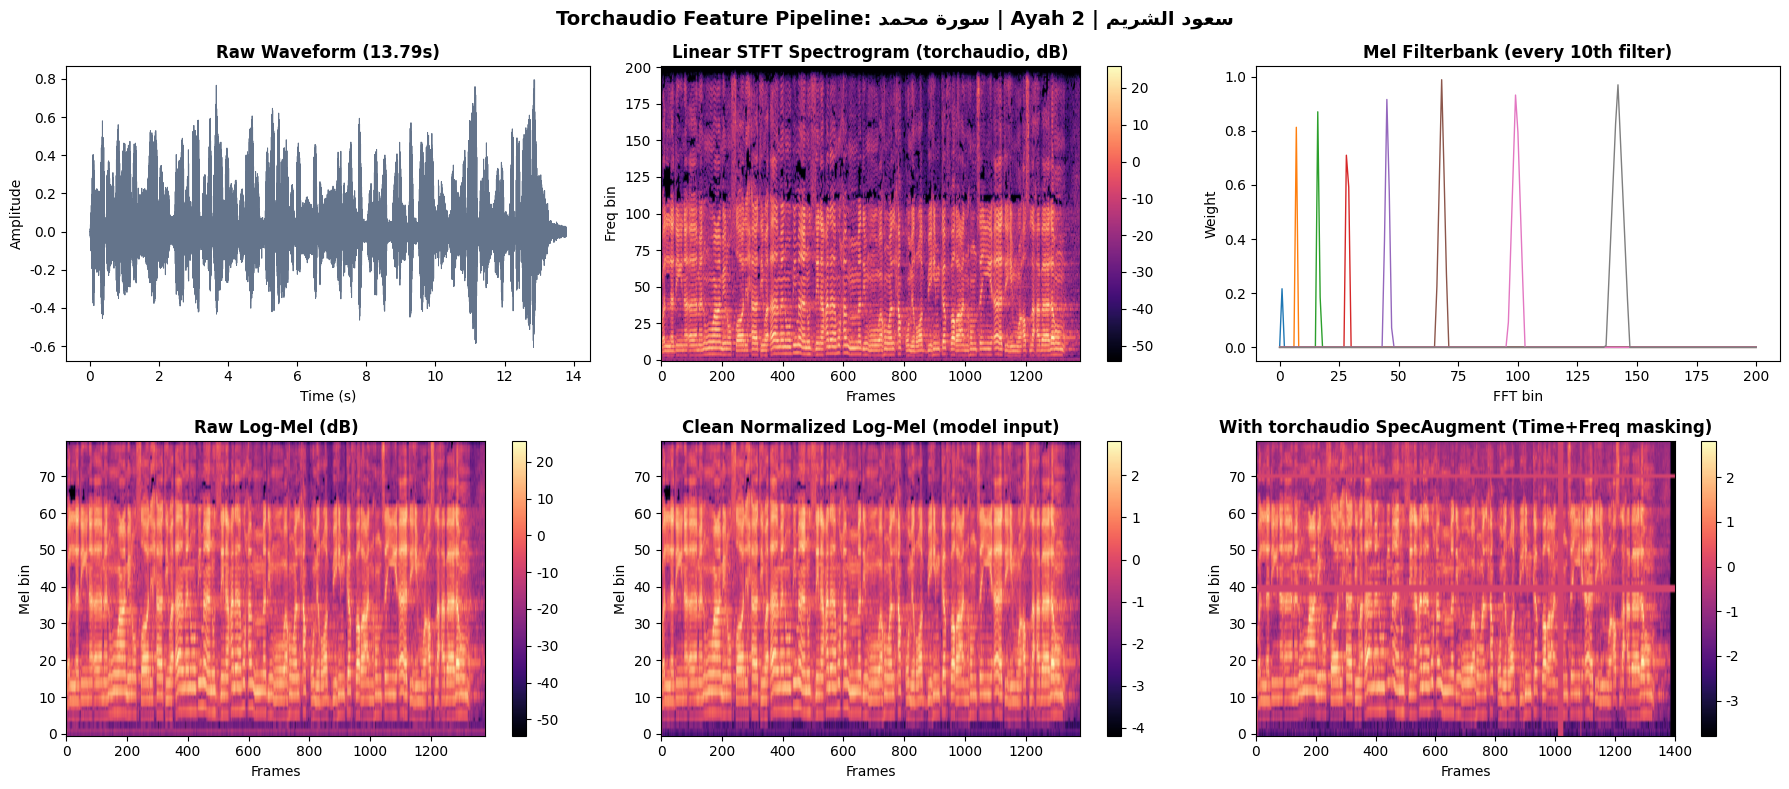

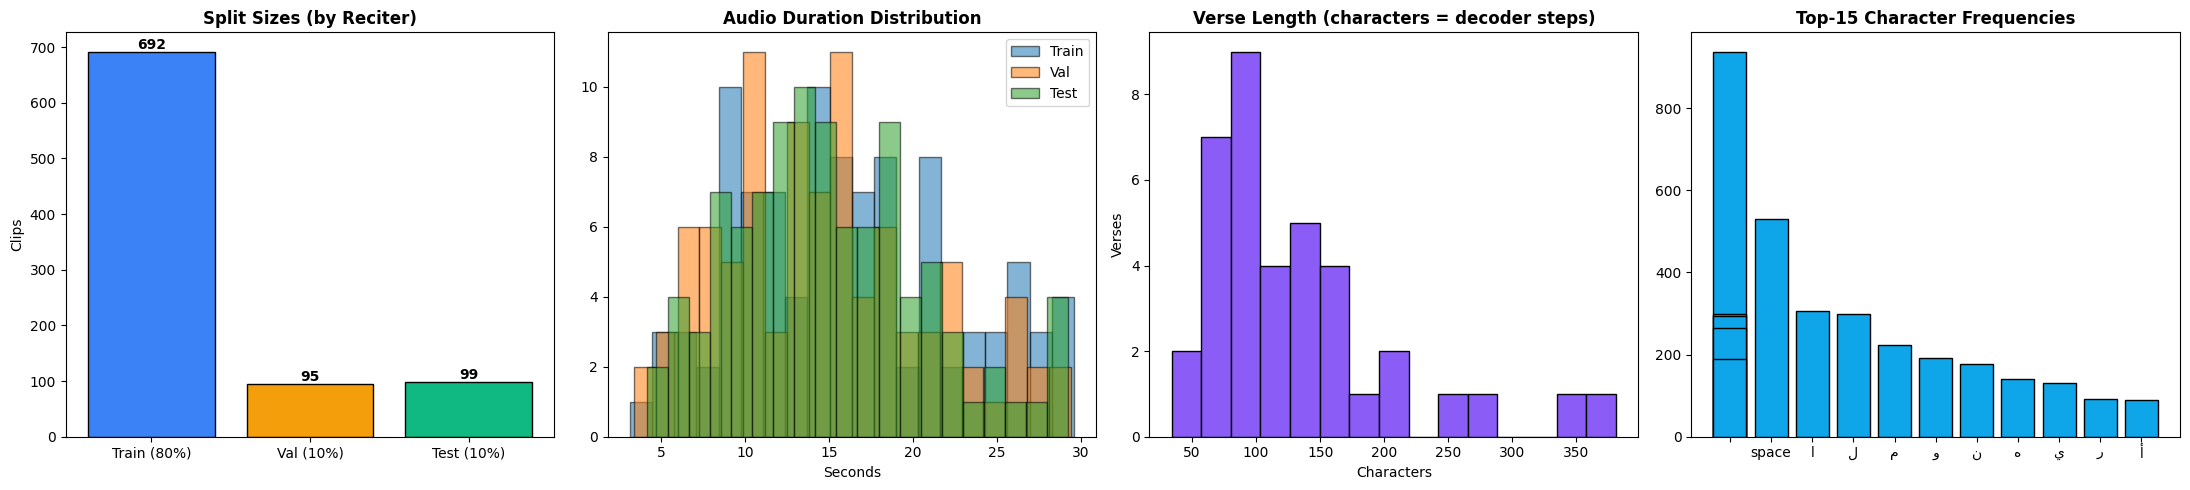

In [12]:
import json
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import arabic_reshaper
from bidi.algorithm import get_display
from IPython.display import display, Audio as IPythonAudio, HTML

matplotlib.rcParams["font.family"] = "sans-serif"
matplotlib.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Tahoma"]
matplotlib.rcParams["axes.unicode_minus"] = False

def shape_ar(text):
    """Reshapes and applies bidirectional layout for Matplotlib rendering."""
    if not text:
        return ""
    reshaped = arabic_reshaper.reshape(str(text))
    return get_display(reshaped)

def raw_ar(text):
    """Returns raw Arabic text for HTML/native browser rendering."""
    return str(text) if text else ""

# Select a representative training example with sufficient length for visualization and listening
sample_vis_idx = min(5, len(train_audio) - 1)
for candidate_idx in range(min(30, len(train_audio))):
    if train_audio[candidate_idx].get("ayah_id", 1) >= 2:
        sample_vis_idx = candidate_idx
        break

sample_row = train_audio[sample_vis_idx]
raw_wav = np.asarray(sample_row["audio"]["array"], dtype=np.float32)
reciter_ar_label = get_arabic_reciter_name(sample_row)
ayah_num_vis = sample_row.get("ayah_id", "-")
ayah_text_vis = preprocess_quran_text(sample_row["ayah_ar"])

# 1. Deterministic Clean Preprocessing (torchaudio biquads, preemphasis, silence trim, fade, peak norm)
clean_tensor = preprocess_waveform(raw_wav, SR)
clean_wav = clean_tensor.cpu().numpy()

# 2. Individual torchaudio augmentations for listening & inspection:
# A. Speed Perturbation (AF.resample: 1.10x faster)
aug_speed_tensor = AF.resample(clean_tensor, orig_freq=int(SR * 1.10), new_freq=SR)
aug_speed = aug_speed_tensor.cpu().numpy()

# B. Pitch Shifting (AF.pitch_shift: +1.5 semitones)
aug_pitch_tensor = AF.pitch_shift(clean_tensor, SR, n_steps=1.5)
aug_pitch = aug_pitch_tensor.cpu().numpy()

# C. Simulated Mosque / Room Reverb (AF.fftconvolve with exponential decay impulse response)
ir_len = int(0.22 * SR)
t_ir = torch.linspace(0.0, 1.0, ir_len)
ir = torch.randn(ir_len) * torch.exp(-6.5 * t_ir)
ir[0] = 1.0
ir = ir / (ir.norm() + 1e-8)
wet_mix = 0.25
reverb_tensor = AF.fftconvolve(clean_tensor, ir)[: clean_tensor.numel()]
aug_reverb_tensor = (1.0 - wet_mix) * clean_tensor + wet_mix * reverb_tensor
aug_reverb = aug_reverb_tensor.cpu().numpy()

# D. Ambient Pink Noise Injection (AF.add_noise: 1/f noise at 22 dB SNR)
white_n = torch.randn(clean_tensor.numel())
spec_n = torch.fft.rfft(white_n)
freqs_n = torch.fft.rfftfreq(clean_tensor.numel())
freqs_n[0] = 1.0
k_pink_n = torch.fft.irfft(spec_n / freqs_n.sqrt(), n=clean_tensor.numel())
pink_n = k_pink_n / (k_pink_n.std() + 1e-8)
snr_tensor = torch.tensor([22.0])
aug_noise_tensor = AF.add_noise(clean_tensor.unsqueeze(0), pink_n.unsqueeze(0), snr_tensor).squeeze(0)
aug_noise = aug_noise_tensor.cpu().numpy()

# E. Combined Multi-Stage Stochastic Augmentation (Full pipeline)
torch.manual_seed(42)
aug_combined_tensor = augment_waveform_torch(clean_tensor.clone(), SR)
aug_combined = aug_combined_tensor.cpu().numpy()

# Spectrograms
wf = torch.from_numpy(raw_wav).float()
mel_raw = amplitude_to_db_transform(mel_spectrogram_transform(wf.unsqueeze(0))).squeeze(0)
mel_clean = extract_log_mel(raw_wav, augment=False).T          # (n_mels, T)
torch.manual_seed(0)
mel_aug = extract_log_mel(raw_wav, augment=True).T             # SpecAugment (time+freq masks)

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
t_axis = np.linspace(0, len(raw_wav) / SR, len(raw_wav))
axes[0, 0].plot(t_axis, raw_wav, color="#64748b", linewidth=0.7)
axes[0, 0].set_title(f"Raw Waveform ({len(raw_wav)/SR:.2f}s)", fontweight="bold")
axes[0, 0].set_xlabel("Time (s)"); axes[0, 0].set_ylabel("Amplitude")

# Torchaudio spectrogram / linear-power STFT view
spec = T.Spectrogram(n_fft=400, hop_length=160, power=2.0)(wf.unsqueeze(0))
spec_db = amplitude_to_db_transform(spec).squeeze(0)
im = axes[0, 1].imshow(spec_db.numpy(), origin="lower", aspect="auto", cmap="magma")
axes[0, 1].set_title("Linear STFT Spectrogram (torchaudio, dB)", fontweight="bold")
axes[0, 1].set_xlabel("Frames"); axes[0, 1].set_ylabel("Freq bin")
fig.colorbar(im, ax=axes[0, 1])

# Mel filterbank (torchaudio.functional.melscale_fbanks)
fb = AF.melscale_fbanks(n_freqs=201, f_min=0.0, f_max=SR / 2, n_mels=N_MELS, sample_rate=SR)
axes[0, 2].plot(fb[:, ::10].numpy(), linewidth=1)
axes[0, 2].set_title("Mel Filterbank (every 10th filter)", fontweight="bold")
axes[0, 2].set_xlabel("FFT bin"); axes[0, 2].set_ylabel("Weight")

for ax, mel, ttl in [
    (axes[1, 0], mel_raw, "Raw Log-Mel (dB)"),
    (axes[1, 1], mel_clean, "Clean Normalized Log-Mel (model input)"),
    (axes[1, 2], mel_aug, "With torchaudio SpecAugment (Time+Freq masking)"),
]:
    im = ax.imshow(mel.numpy(), origin="lower", aspect="auto", cmap="magma")
    ax.set_title(ttl, fontweight="bold")
    ax.set_xlabel("Frames"); ax.set_ylabel("Mel bin")
    fig.colorbar(im, ax=ax)

# Build cleanly directed suptitle blocks to prevent RTL boundary breaking
title_str = f"Torchaudio Feature Pipeline: {shape_ar(SURAH_NAME_AR)} | Ayah {ayah_num_vis} | {shape_ar(reciter_ar_label)}"
fig.suptitle(title_str, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "torchaudio_features.png"), dpi=150, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------------------------
# Interactive Audio Players: Listen to Raw vs. Preprocessed vs. Augmentations
# ---------------------------------------------------------------------------
display(HTML(f"""
<div style="background-color: #f8fafc; border: 1px solid #cbd5e1; border-radius: 8px; padding: 14px 18px; margin: 12px 0 16px 0;">
  <h3 style="color: #0f172a; margin: 0 0 8px 0; font-size: 18px;">
    🎧 Interactive Audio Player Comparison — {raw_ar(SURAH_NAME_AR)} (Ayah {ayah_num_vis})
  </h3>
  <p style="margin: 4px 0; font-size: 14px; color: #334155;">
    <b>Reciter:</b> {raw_ar(reciter_ar_label)} &nbsp;|&nbsp; <b>ID:</b> <code>{sample_row.get(reciter_col, '-')}</code>
  </p>
  <p style="margin: 6px 0 0 0; font-size: 16px; direction: rtl; text-align: right; color: #0284c7; font-weight: bold; font-family: 'Amiri', 'Traditional Arabic', serif;">
    {raw_ar(ayah_text_vis)}
  </p>
</div>
"""))

display(HTML(f"<b>1. Raw Original Recording</b> <span style='color:#64748b;'>({len(raw_wav)/SR:.2f}s)</span>:"))
display(IPythonAudio(raw_wav, rate=SR))

display(HTML(f"<b>2. Clean Preprocessed Audio</b> <span style='color:#2563eb;'>(torchaudio bandpass 65-7600Hz + pre-emphasis + silence trim + 15ms fade + peak norm - {len(clean_wav)/SR:.2f}s)</span>:"))
display(IPythonAudio(clean_wav, rate=SR))

display(HTML(f"<b>3. Augmentation: Speed Perturbation</b> <span style='color:#d97706;'>(torchaudio AF.resample 1.10x faster - {len(aug_speed)/SR:.2f}s)</span>:"))
display(IPythonAudio(aug_speed, rate=SR))

display(HTML(f"<b>4. Augmentation: Pitch Shifted</b> <span style='color:#9333ea;'>(torchaudio AF.pitch_shift +1.5 semitones - {len(aug_pitch)/SR:.2f}s)</span>:"))
display(IPythonAudio(aug_pitch, rate=SR))

display(HTML(f"<b>5. Augmentation: Simulated Mosque / Room Reverb</b> <span style='color:#059669;'>(torchaudio AF.fftconvolve with exponential decay IR - {len(aug_reverb)/SR:.2f}s)</span>:"))
display(IPythonAudio(aug_reverb, rate=SR))

display(HTML(f"<b>6. Augmentation: Ambient Pink Noise Injected</b> <span style='color:#ea580c;'>(torchaudio AF.add_noise with 1/f pink noise at SNR 22 dB - {len(aug_noise)/SR:.2f}s)</span>:"))
display(IPythonAudio(aug_noise, rate=SR))

display(HTML(f"<b>7. Augmentation: Multi-Stage Combined Augmentation</b> <span style='color:#16a34a;'>(Speed + Pitch + Reverb + Noise + Temporal Shift + SpecAugment input - {len(aug_combined)/SR:.2f}s)</span>:"))
display(IPythonAudio(aug_combined, rate=SR))

# Dataset statistics: split sizes, durations, transcript lengths, vocab frequencies
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
split_sizes = [len(train_audio), len(eval_audio), len(test_audio)]
bars = axes[0].bar(["Train (80%)", "Val (10%)", "Test (10%)"], split_sizes,
                   color=["#3b82f6", "#f59e0b", "#10b981"], edgecolor="black")
for b, c in zip(bars, split_sizes):
    axes[0].text(b.get_x() + b.get_width() / 2, b.get_height(), str(c), ha="center", va="bottom", fontweight="bold")
axes[0].set_title("Split Sizes (by Reciter)", fontweight="bold"); axes[0].set_ylabel("Clips")

durs = {}
for name, ds in [("Train", train_audio), ("Val", eval_audio), ("Test", test_audio)]:
    idxs = np.linspace(0, len(ds) - 1, min(100, len(ds)), dtype=int)
    durs[name] = [len(ds[int(i)]["audio"]["array"]) / SR for i in idxs]
    axes[1].hist(durs[name], bins=20, alpha=0.55, label=name, edgecolor="black")
axes[1].set_title("Audio Duration Distribution", fontweight="bold")
axes[1].set_xlabel("Seconds"); axes[1].legend()

verse_texts = {a: preprocess_quran_text(t) for a, t in zip(raw_dataset["ayah_id"], raw_dataset["ayah_ar"])}
axes[2].hist([len(t) for t in verse_texts.values()], bins=15, color="#8b5cf6", edgecolor="black")
axes[2].set_title("Verse Length (characters = decoder steps)", fontweight="bold")
axes[2].set_xlabel("Characters"); axes[2].set_ylabel("Verses")

from collections import Counter
char_freq = Counter("".join(verse_texts.values())).most_common(15)
axes[3].bar([shape_ar(c) if c.strip() else "space" for c, _ in char_freq], [n for _, n in char_freq],
            color="#0ea5e9", edgecolor="black")
axes[3].set_title("Top-15 Character Frequencies", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "dataset_statistics.png"), dpi=150, bbox_inches="tight")
plt.show()

## Step 8 — Training & Evaluation Loop for سورة محمد

In [14]:
EPOCHS = 300
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-2
GRAD_ACCUM_STEPS = 1

criterion = nn.CrossEntropyLoss(
    ignore_index=tokenizer.pad_id,
    label_smoothing=0.02,
)
ctc_criterion = nn.CTCLoss(
    blank=tokenizer.pad_id,
    zero_infinity=True,
)
CTC_WEIGHT = 0.30

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    betas=(0.9, 0.999),
    eps=1e-8,
    weight_decay=WEIGHT_DECAY,
    foreach=True,
)

# One scheduler step per optimizer update
updates_per_epoch = (len(train_loader) + GRAD_ACCUM_STEPS - 1) // GRAD_ACCUM_STEPS
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=LEARNING_RATE,
    epochs=EPOCHS,
    steps_per_epoch=updates_per_epoch,
    pct_start=0.10,
    anneal_strategy="cos",
    cycle_momentum=False,
    div_factor=10.0,
    final_div_factor=100.0,
)
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available(),
)

import copy

class ModelEMA:
    """Exponential Moving Average (EMA) of model weights for superior validation stability."""
    def __init__(self, model, decay=0.999):
        self.decay = decay
        self.ema_model = copy.deepcopy(model).eval()
        for p in self.ema_model.parameters():
            p.requires_grad = False

    @torch.no_grad()
    def update(self, model):
        for ema_p, p in zip(self.ema_model.parameters(), model.parameters()):
            ema_p.data.mul_(self.decay).add_(p.data, alpha=1.0 - self.decay)

ema = ModelEMA(model, decay=0.999)

best_val_score = float("inf")
best_val_wer = float("inf")
best_val_cer = float("inf")

# Training history used by the visualization suite
history = {
    "epoch": [], "train_loss": [], "lr": [], "grad_norm": [],
    "val_epoch": [], "val_loss": [], "val_wer": [], "val_cer": [], "val_cer_exact": [],
    "val_ctc_wer": [], "val_ctc_cer": [],
}

# Optional: Resume training from existing checkpoint if session was interrupted
START_EPOCH = 1
RESUME_TRAINING = False  # Set to True to resume training from previous checkpoint
if RESUME_TRAINING and os.path.isfile(CHECKPOINT_PATH):
    ckpt = torch.load(CHECKPOINT_PATH, map_location=device)
    if isinstance(ckpt, dict) and "model_state_dict" in ckpt:
        model.load_state_dict(ckpt["model_state_dict"])
        if "optimizer_state_dict" in ckpt:
            optimizer.load_state_dict(ckpt["optimizer_state_dict"])
        if "scheduler_state_dict" in ckpt:
            scheduler.load_state_dict(ckpt["scheduler_state_dict"])
        if "scaler_state_dict" in ckpt:
            scaler.load_state_dict(ckpt["scaler_state_dict"])
        best_val_score = ckpt.get("best_val_score", float("inf"))
        best_val_wer = ckpt.get("best_val_wer", float("inf"))
        best_val_cer = ckpt.get("best_val_cer", float("inf"))
        history = ckpt.get("history", history)
        START_EPOCH = ckpt.get("epoch", 0) + 1
        print(f"Resuming training from epoch {START_EPOCH} (Previous Best Val Score: {best_val_score:.2f} | WER: {best_val_wer:.2f}% | CER: {best_val_cer:.2f}%)")

def evaluate_split(model, dataloader, compute_metrics=True, max_len=300):
    """
    Evaluates loss (CE + auxiliary CTC) and optionally WER/CER on a dataloader.
    Runs under torch.amp.autocast with anti-repetition decoding and computes pure CTC baseline for comparison.
    """
    model.eval()
    total_loss = 0.0
    all_refs, all_preds = [], []
    all_ctc_preds = []

    with torch.no_grad():
        for (
            padded_mels,
            mel_lengths,
            tgt_input,
            tgt_labels,
            padded_ctc_targets,
            ctc_lengths,
            raw_texts,
            _,
            _,
        ) in dataloader:
            padded_mels = padded_mels.to(device)
            mel_lengths = mel_lengths.to(device)
            tgt_input = tgt_input.to(device)
            tgt_labels = tgt_labels.to(device)
            padded_ctc_targets = padded_ctc_targets.to(device)
            ctc_lengths = ctc_lengths.to(device)

            with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
                logits, ctc_logits, enc_lengths = model(padded_mels, mel_lengths, tgt_input, return_ctc=True)
                ce_loss = criterion(logits.reshape(-1, logits.size(-1)), tgt_labels.reshape(-1))

            # CTCLoss in float32 outside autocast prevents numerical underflow in FP16:
            ctc_log_probs = F.log_softmax(ctc_logits.float(), dim=-1).transpose(0, 1)
            ctc_loss = ctc_criterion(ctc_log_probs, padded_ctc_targets, enc_lengths, ctc_lengths)
            loss = (1.0 - CTC_WEIGHT) * ce_loss + CTC_WEIGHT * ctc_loss

            total_loss += loss.item()

            if compute_metrics:
                gen_ids = model.greedy_decode(
                    padded_mels,
                    mel_lengths,
                    sos_id=tokenizer.sos_id,
                    eos_id=tokenizer.eos_id,
                    max_len=max_len,
                    no_repeat_ngram_size=4,
                    repetition_penalty=1.45,
                )
                for ref_str, pred_seq in zip(raw_texts, gen_ids):
                    all_refs.append(preprocess_quran_text(ref_str))
                    all_preds.append(tokenizer.decode(pred_seq))

                # Pure CTC greedy decoding baseline (strictly bounded to valid acoustic lengths)
                ctc_toks = torch.argmax(ctc_logits, dim=-1)
                for b in range(padded_mels.size(0)):
                    c_seq, prev = [], -1
                    cur_len = enc_lengths[b].item()
                    for tok in ctc_toks[b, :cur_len].tolist():
                        if tok != prev:
                            if tok not in (tokenizer.pad_id, tokenizer.sos_id, tokenizer.eos_id):
                                c_seq.append(tok)
                            prev = tok
                    all_ctc_preds.append(tokenizer.decode(c_seq))

    avg_loss = total_loss / max(1, len(dataloader))
    if compute_metrics and all_refs:
        norm_refs = [normalize_arabic(r) for r in all_refs]
        norm_preds = [normalize_arabic(p) for p in all_preds]
        norm_ctc = [normalize_arabic(p) for p in all_ctc_preds]

        # Corpus-Level metrics (Official JiWER standard)
        wer_norm = 100.0 * jiwer.wer(norm_refs, norm_preds)
        cer_norm = 100.0 * jiwer.cer(norm_refs, norm_preds)
        cer_exact = 100.0 * jiwer.cer(all_refs, all_preds)

        ctc_wer = 100.0 * jiwer.wer(norm_refs, norm_ctc)
        ctc_cer = 100.0 * jiwer.cer(norm_refs, norm_ctc)
    else:
        wer_norm, cer_norm, cer_exact = None, None, None
        ctc_wer, ctc_cer = None, None

    return avg_loss, wer_norm, cer_norm, cer_exact, ctc_wer, ctc_cer, all_refs, all_preds


print(f"Starting optimized training on {SURAH_NAME_AR} for {EPOCHS} epochs ({len(train_loader)} batches/epoch)...")
print("  Accelerations: In-Memory Mel Caching + Length Bucketing + FP16 Mixed Precision + Anti-Repetition Decoders\n")

for epoch in range(START_EPOCH, EPOCHS + 1):
    model.train()
    running_loss = 0.0
    running_gn = 0.0

    optimizer.zero_grad(set_to_none=True)
    for step_idx, (
        padded_mels,
        mel_lengths,
        tgt_input,
        tgt_labels,
        padded_ctc_targets,
        ctc_lengths,
        _,
        _,
        _,
    ) in enumerate(train_loader):
        padded_mels = padded_mels.to(device)
        mel_lengths = mel_lengths.to(device)
        tgt_input = tgt_input.to(device)
        tgt_labels = tgt_labels.to(device)
        padded_ctc_targets = padded_ctc_targets.to(device)
        ctc_lengths = ctc_lengths.to(device)

        with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
            logits, ctc_logits, enc_lengths = model(padded_mels, mel_lengths, tgt_input, return_ctc=True)
            ce_loss = criterion(logits.reshape(-1, logits.size(-1)), tgt_labels.reshape(-1))

        # Full float32 precision for CTCLoss prevents vanishing/zero gradients in FP16:
        ctc_log_probs = F.log_softmax(ctc_logits.float(), dim=-1).transpose(0, 1)
        ctc_loss = ctc_criterion(ctc_log_probs, padded_ctc_targets, enc_lengths, ctc_lengths)

        loss = (1.0 - CTC_WEIGHT) * ce_loss + CTC_WEIGHT * ctc_loss
        if GRAD_ACCUM_STEPS > 1:
            loss = loss / GRAD_ACCUM_STEPS

        scaler.scale(loss).backward()
        running_loss += loss.item() * (GRAD_ACCUM_STEPS if GRAD_ACCUM_STEPS > 1 else 1.0)

        if (step_idx + 1) % GRAD_ACCUM_STEPS == 0 or (step_idx + 1) == len(train_loader):
            scaler.unscale_(optimizer)
            gn = torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.5)
            old_scale = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()

            # Advance the scheduler and EMA only if the optimizer update succeeded
            if scaler.get_scale() >= old_scale:
                scheduler.step()
                ema.update(model)

            optimizer.zero_grad(set_to_none=True)
            running_gn += float(gn)

    train_loss = running_loss / max(1, len(train_loader))
    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["lr"].append(optimizer.param_groups[0]["lr"])
    history["grad_norm"].append(running_gn / max(1, updates_per_epoch))

    # Evaluate full WER/CER periodically (epoch 1, every 5 epochs, and final epoch)
    should_eval_metrics = (epoch % 5 == 0 or epoch == 1 or epoch == EPOCHS)
    val_loss, val_wer, val_cer, val_cer_exact, ctc_wer, ctc_cer, _, _ = evaluate_split(
        model, val_loader, compute_metrics=should_eval_metrics, max_len=300
    )

    if should_eval_metrics:
        history["val_epoch"].append(epoch)
        history["val_loss"].append(val_loss)
        history["val_wer"].append(val_wer)
        history["val_cer"].append(val_cer)
        history["val_cer_exact"].append(val_cer_exact)
        history["val_ctc_wer"].append(ctc_wer)
        history["val_ctc_cer"].append(ctc_cer)
        print(
            f"Epoch [{epoch:02d}/{EPOCHS:02d}] | "
            f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
            f"Val WER: {val_wer:.2f}% (CTC: {ctc_wer:.2f}%) | Val CER: {val_cer:.2f}% (CTC: {ctc_cer:.2f}%) | "
            f"Exact CER: {val_cer_exact:.2f}% | LR: {optimizer.param_groups[0]['lr']:.2e}"
        )
        # Balanced checkpoint selection: prioritizes lower WER to avoid repetition loop artifacts
        val_score = 0.60 * val_wer + 0.40 * val_cer
        if val_score < best_val_score:
            best_val_score = val_score
            best_val_wer = val_wer
            best_val_cer = val_cer
            checkpoint_payload = {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "ema_model_state_dict": ema.ema_model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "scaler_state_dict": scaler.state_dict(),
                "best_val_score": best_val_score,
                "best_val_wer": best_val_wer,
                "best_val_cer": best_val_cer,
                "history": history,
            }
            torch.save(checkpoint_payload, CHECKPOINT_PATH)
            print(f"  --> Best balanced checkpoint saved! (Score: {best_val_score:.2f} | Val WER: {val_wer:.2f}% | Val CER: {val_cer:.2f}%)")
    else:
        print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | LR: {optimizer.param_groups[0]['lr']:.2e}")

with open(os.path.join(PROJECT_DIR, "training_history.json"), "w") as f:
    json.dump(history, f)

Starting optimized training on سورة محمد for 300 epochs (44 batches/epoch)...
  Accelerations: In-Memory Mel Caching + Length Bucketing + FP16 Mixed Precision + Anti-Repetition Decoders

Epoch [01/300] | Train Loss: 0.7453 | Val Loss: 0.6999 | Val WER: 82.33% (CTC: 79.30%) | Val CER: 53.87% (CTC: 29.63%) | Exact CER: 53.01% | LR: 3.07e-05
  --> Best balanced checkpoint saved! (Score: 70.94 | Val WER: 82.33% | Val CER: 53.87%)
Epoch [02/300] | Train Loss: 0.7417 | Val Loss: 0.7003 | LR: 3.30e-05
Epoch [03/300] | Train Loss: 0.7386 | Val Loss: 0.6929 | LR: 3.66e-05
Epoch [04/300] | Train Loss: 0.7357 | Val Loss: 0.6979 | LR: 4.17e-05
Epoch [05/300] | Train Loss: 0.7280 | Val Loss: 0.6849 | Val WER: 80.04% (CTC: 78.39%) | Val CER: 52.45% (CTC: 28.96%) | Exact CER: 51.89% | LR: 4.81e-05
  --> Best balanced checkpoint saved! (Score: 69.00 | Val WER: 80.04% | Val CER: 52.45%)
Epoch [06/300] | Train Loss: 0.7296 | Val Loss: 0.6947 | LR: 5.58e-05
Epoch [07/300] | Train Loss: 0.7251 | Val Loss:

## Step 9 — Final Evaluation on Held-Out Testing Split (10%) & Sample Predictions

In [15]:
if os.path.isfile(CHECKPOINT_PATH):
    ckpt = torch.load(CHECKPOINT_PATH, map_location=device)
    if isinstance(ckpt, dict) and "model_state_dict" in ckpt:
        model.load_state_dict(ckpt["model_state_dict"])
        print(f"Loaded best model checkpoint from: {CHECKPOINT_PATH} (Epoch {ckpt.get('epoch', '?')}, Val WER: {ckpt.get('best_val_wer', '?')}%, Val CER: {ckpt.get('best_val_cer', '?')}%)")
    else:
        model.load_state_dict(ckpt)
        print("Loaded best model checkpoint from:", CHECKPOINT_PATH)

test_loss, test_wer, test_cer, test_cer_exact, test_ctc_wer, test_ctc_cer, test_refs, test_preds = evaluate_split(
    model, test_loader, compute_metrics=True
)
norm_test_refs = [normalize_arabic(r) for r in test_refs]

# Comparative Decoding Benchmark: Pure CTC, Beam Search (5, 10, 20), Joint CTC/Attn, and Decoder
benchmark_results = [
    {"Strategy": "1. Autoregressive Decoder (Greedy)", "WER (%)": round(test_wer, 2), "CER (%)": round(test_cer, 2)},
    {"Strategy": "2. Pure CTC Greedy Baseline", "WER (%)": round(test_ctc_wer, 2), "CER (%)": round(test_ctc_cer, 2)},
]

# 3. CTC Beam Search at B = 5, 10, 20
ctc_beam_samples = {}
for b_size in [5, 10, 20]:
    b_preds = []
    for padded_mels, mel_lengths, _, _, _, _, _, _, _ in test_loader:
        gen = model.ctc_beam_decode(
            padded_mels.to(device),
            mel_lengths.to(device),
            sos_id=tokenizer.sos_id,
            eos_id=tokenizer.eos_id,
            beam_size=b_size,
        )
        for p in gen:
            b_preds.append(tokenizer.decode(p))
    norm_p = [normalize_arabic(p) for p in b_preds]
    b_wer = round(100.0 * jiwer.wer(norm_test_refs, norm_p), 2)
    b_cer = round(100.0 * jiwer.cer(norm_test_refs, norm_p), 2)
    benchmark_results.append({
        "Strategy": f"3. CTC Prefix Beam Search (B={b_size})",
        "WER (%)": b_wer,
        "CER (%)": b_cer,
    })
    ctc_beam_samples[b_size] = b_preds

# 4. Joint CTC/Attention Beam Search at ctc_weight = 0.50, 0.65, 0.80 (B = 10)
joint_samples = {}
for c_w in [0.50, 0.65, 0.80]:
    j_preds = []
    for padded_mels, mel_lengths, _, _, _, _, _, _, _ in test_loader:
        gen = model.joint_ctc_attention_decode(
            padded_mels.to(device),
            mel_lengths.to(device),
            sos_id=tokenizer.sos_id,
            eos_id=tokenizer.eos_id,
            beam_size=10,
            ctc_weight=c_w,
        )
        for p in gen:
            j_preds.append(tokenizer.decode(p))
    norm_p = [normalize_arabic(p) for p in j_preds]
    j_wer = round(100.0 * jiwer.wer(norm_test_refs, norm_p), 2)
    j_cer = round(100.0 * jiwer.cer(norm_test_refs, norm_p), 2)
    benchmark_results.append({
        "Strategy": f"4. Joint CTC/Attn (B=10, w={c_w})",
        "WER (%)": j_wer,
        "CER (%)": j_cer,
    })
    joint_samples[c_w] = j_preds

bench_df = pd.DataFrame(benchmark_results)
print("\n" + "=" * 80)
print(f"DECODING BENCHMARK ON HELD-OUT TEST SPLIT ({SURAH_NAME_AR} - Unseen Reciters):")
print("=" * 80)
print(bench_df.to_string(index=False))
print("=" * 80 + "\n")

# Display qualitative side-by-side comparison for first 5 test samples
best_joint_preds = joint_samples.get(0.65, list(joint_samples.values())[0])
best_ctc_beam_preds = ctc_beam_samples.get(10, list(ctc_beam_samples.values())[0])
for i in range(min(5, len(test_refs))):
    print(f"--- Sample {i+1} ---")
    print("Reference          :", test_refs[i])
    print("Decoder Greedy     :", test_preds[i])
    print("CTC Beam (B=10)    :", best_ctc_beam_preds[i])
    print("Joint CTC/Attn     :", best_joint_preds[i])
    print()

Loaded best model checkpoint from: /content/drive/MyDrive/quran-hybrid-asr-muhammad/best_hybrid_model.pt (Epoch 210, Val WER: 34.065934065934066%, Val CER: 15.861837692823608%)

DECODING BENCHMARK ON HELD-OUT TEST SPLIT (سورة محمد - Unseen Reciters):
                          Strategy  WER (%)  CER (%)
1. Autoregressive Decoder (Greedy)    37.83    18.10
       2. Pure CTC Greedy Baseline    17.51     5.02
   3. CTC Prefix Beam Search (B=5)    17.25     4.89
  3. CTC Prefix Beam Search (B=10)    17.25     4.91
  3. CTC Prefix Beam Search (B=20)    17.16     4.86
   4. Joint CTC/Attn (B=10, w=0.5)    14.45     4.38
  4. Joint CTC/Attn (B=10, w=0.65)    14.45     4.41
   4. Joint CTC/Attn (B=10, w=0.8)    14.80     4.51

--- Sample 1 ---
Reference          : سَيَهْدِيهِمْ وَيُصْلِحُ بَالَهُمْ
Decoder Greedy     : سَيَهْدِيهِمْ وَيُصْلِحُ بَالَهُمْ
CTC Beam (B=10)    : سَيَهْدِيهِمْ وَيُصْلِحُ بَالَهُمْ
Joint CTC/Attn     : سَيَهْدِيهِمْ وَيُصْلِحُ بَالَهُمْ

--- Sample 2 ---
Reference   

## Step 10 — Training Progression Dashboard (Loss, WER, CER, LR & Gradient Norm)

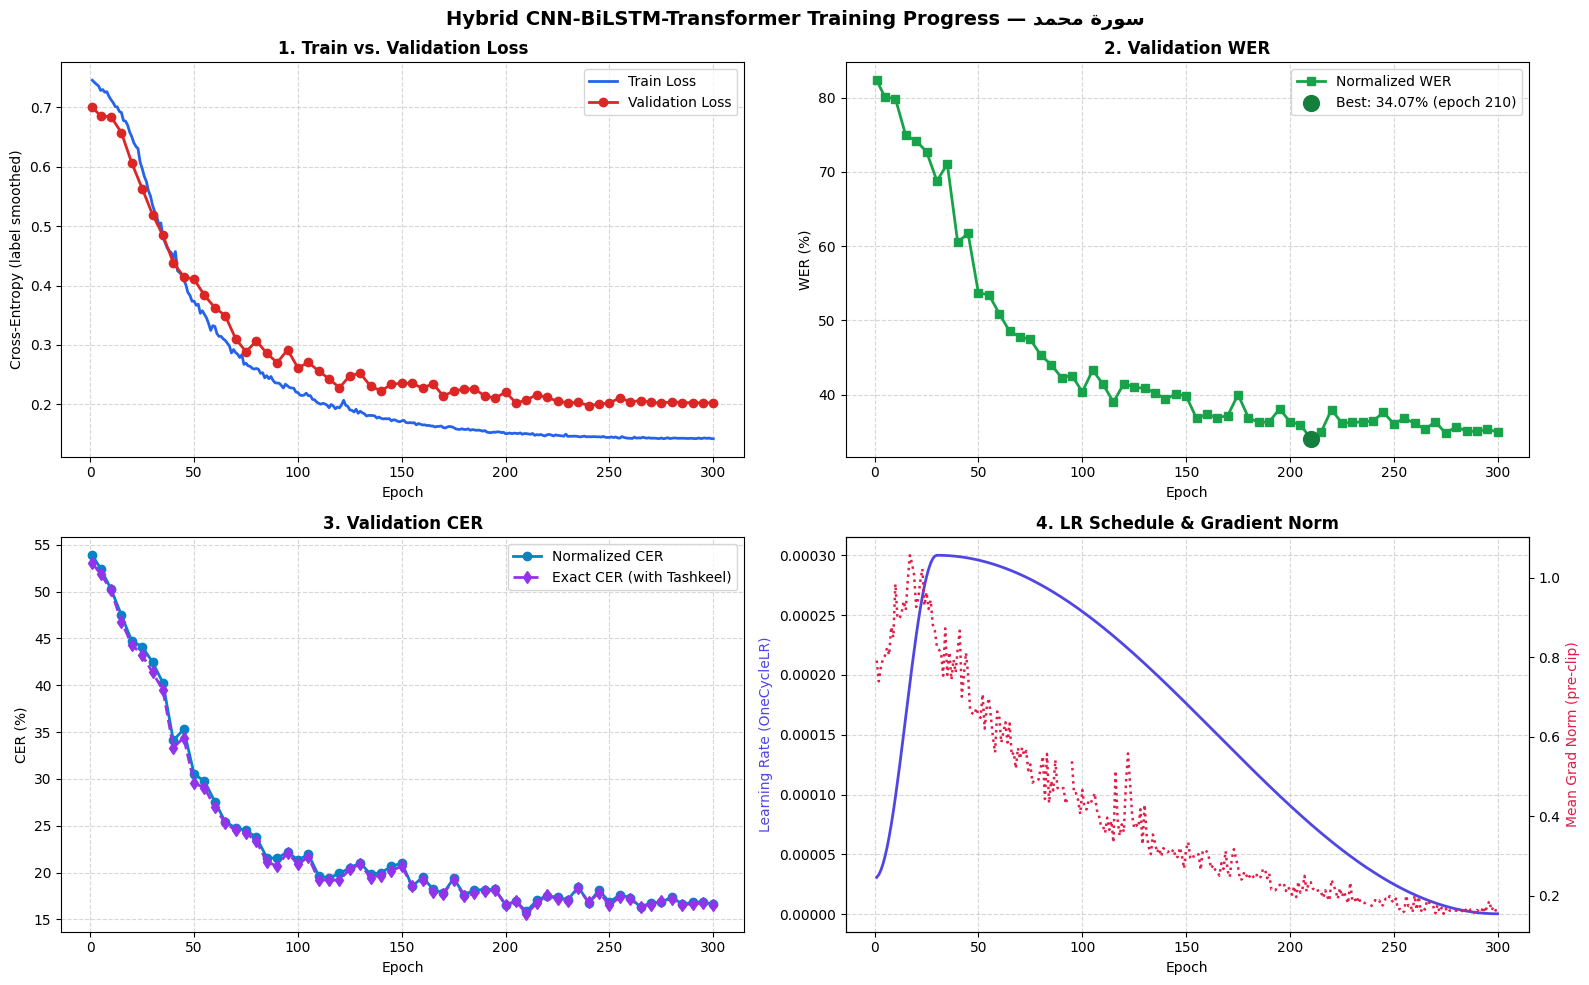

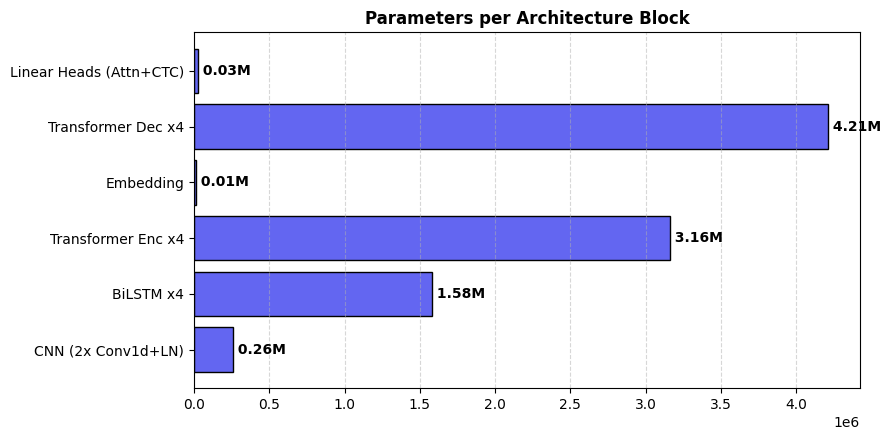

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

axes[0, 0].plot(history["epoch"], history["train_loss"], color="#2563eb", linewidth=2, label="Train Loss")
axes[0, 0].plot(history["val_epoch"], history["val_loss"], color="#dc2626", marker="o", linewidth=2, label="Validation Loss")
axes[0, 0].set_title("1. Train vs. Validation Loss", fontweight="bold")
axes[0, 0].set_xlabel("Epoch"); axes[0, 0].set_ylabel("Cross-Entropy (label smoothed)")
axes[0, 0].legend(); axes[0, 0].grid(True, linestyle="--", alpha=0.5)

axes[0, 1].plot(history["val_epoch"], history["val_wer"], color="#16a34a", marker="s", linewidth=2, label="Normalized WER")
bi = int(np.argmin(history["val_wer"]))
axes[0, 1].scatter([history["val_epoch"][bi]], [history["val_wer"][bi]], s=130, color="#15803d", zorder=5,
                   label=f"Best: {history['val_wer'][bi]:.2f}% (epoch {history['val_epoch'][bi]})")
axes[0, 1].set_title("2. Validation WER", fontweight="bold")
axes[0, 1].set_xlabel("Epoch"); axes[0, 1].set_ylabel("WER (%)")
axes[0, 1].legend(); axes[0, 1].grid(True, linestyle="--", alpha=0.5)

axes[1, 0].plot(history["val_epoch"], history["val_cer"], color="#0284c7", marker="o", linewidth=2, label="Normalized CER")
axes[1, 0].plot(history["val_epoch"], history["val_cer_exact"], color="#9333ea", marker="d", linestyle="--", linewidth=2, label="Exact CER (with Tashkeel)")
axes[1, 0].set_title("3. Validation CER", fontweight="bold")
axes[1, 0].set_xlabel("Epoch"); axes[1, 0].set_ylabel("CER (%)")
axes[1, 0].legend(); axes[1, 0].grid(True, linestyle="--", alpha=0.5)

axes[1, 1].plot(history["epoch"], history["lr"], color="#4f46e5", linewidth=2)
axes[1, 1].set_ylabel("Learning Rate (OneCycleLR)", color="#4f46e5")
axes[1, 1].set_xlabel("Epoch"); axes[1, 1].grid(True, linestyle="--", alpha=0.5)
ax_gn = axes[1, 1].twinx()
ax_gn.plot(history["epoch"], history["grad_norm"], color="#e11d48", linestyle=":", linewidth=1.8)
ax_gn.set_ylabel("Mean Grad Norm (pre-clip)", color="#e11d48")
axes[1, 1].set_title("4. LR Schedule & Gradient Norm", fontweight="bold")

fig.suptitle(f"Hybrid CNN-BiLSTM-Transformer Training Progress — {shape_ar(SURAH_NAME_AR)}", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "training_progression.png"), dpi=150, bbox_inches="tight")
plt.show()

# Parameter budget per architectural block
blocks = {
    "CNN (2x Conv1d+LN)": [model.conv1, model.ln1, model.conv2, model.ln2],
    "BiLSTM x4": [model.bilstm_pre_norm, model.deep_bilstm, model.bilstm_norm],
    "Transformer Enc x4": [model.transformer_encoder],
    "Embedding": [model.token_embedding],
    "Transformer Dec x4": [model.transformer_decoder],
    "Linear Heads (Attn+CTC)": [model.output_head, model.ctc_head],
}
param_counts = {k: sum(p.numel() for m in v for p in m.parameters()) for k, v in blocks.items()}
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(list(param_counts.keys()), list(param_counts.values()), color="#6366f1", edgecolor="black")
for b, c in zip(bars, param_counts.values()):
    ax.text(c, b.get_y() + b.get_height() / 2, f" {c/1e6:.2f}M", va="center", fontweight="bold")
ax.set_title("Parameters per Architecture Block", fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "parameter_budget.png"), dpi=150, bbox_inches="tight")
plt.show()

## Step 11 — Detailed Evaluation (Validation 10%) & Testing (10%): Per-Sample, Per-Reciter, Alignment

EVALUATION SUMMARY — سورة محمد (ID: 47): Corpus-Level vs Per-Verse Means
               Val (Corpus-Level)  Val (Per-Verse Mean)  Test (Corpus-Level)  Test (Per-Verse Mean)
Norm WER (%)                34.07                 29.08                37.83                  32.43
Exact WER (%)               35.99                 31.21                39.21                  34.14
Norm CER (%)                15.86                 12.77                18.10                  14.82
Exact CER (%)               15.61                 12.62                17.88                  14.75


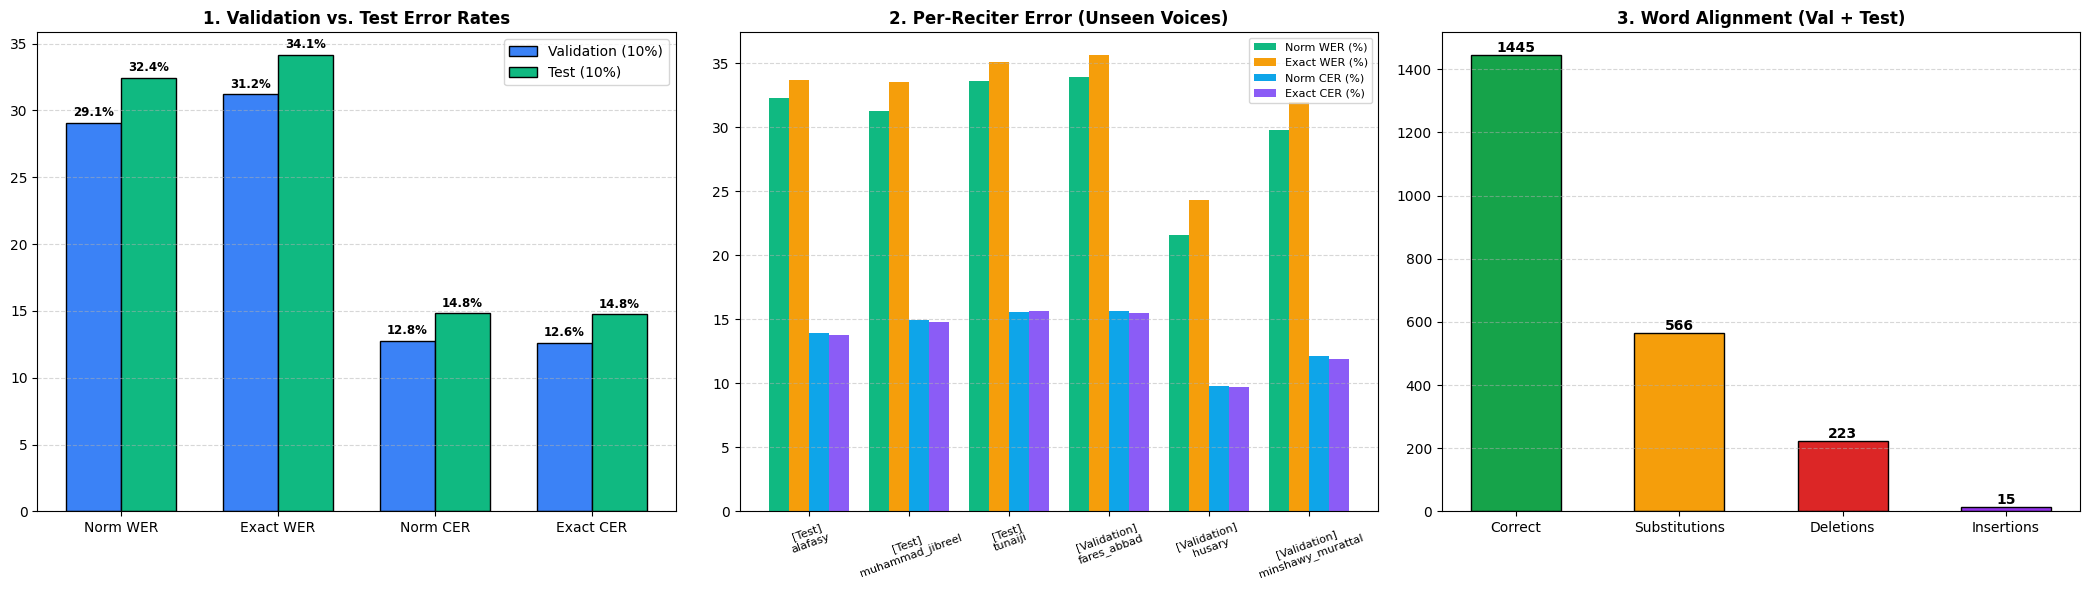

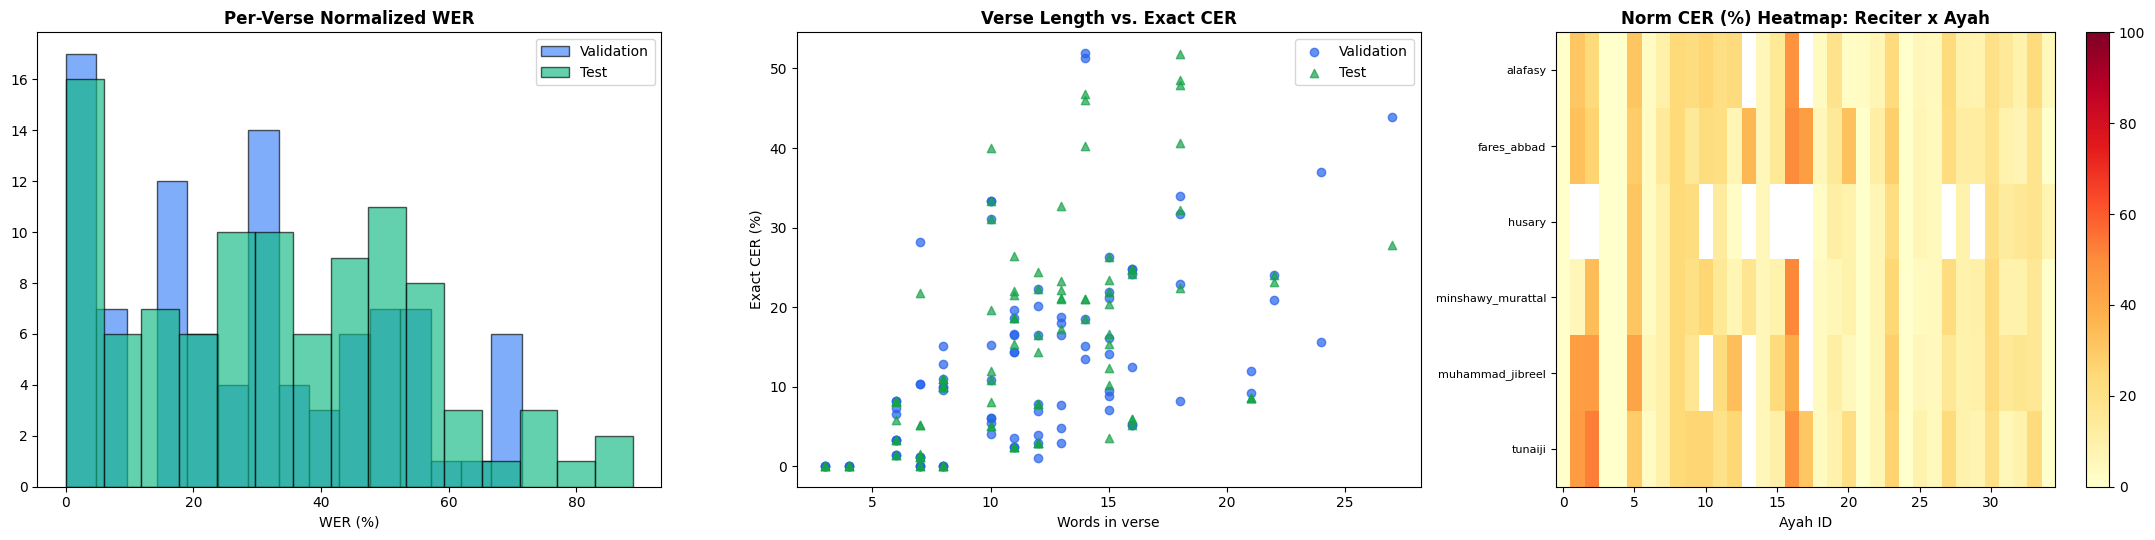

,Split,Ayah ID,Reciter,Words,Norm WER (%),Exact WER (%),Norm CER (%),Exact CER (%),Reference,Predicted
169,Test,3,tunaiji,18,77.780000,78.950000,53.060000,51.760000,ذَٰلِكَ بِأَنَّ الَّذِينَ كَفَرُوا اتَّبَعُوا الْبَاطِلَ وَأَنَّ الَّذِينَ آمَنُوا اتَّبَعُوا الْحَقَّ مِن رَّبِّهِمْ ۚ كَذَٰلِكَ يَضْرِبُ اللَّهُ لِلنَّاسِ أَمْثَالَهُمْ,ذَٰلِكَ بِأَنَّ الَّذِينَ كَفَرُوا اتَّبَعُواطِلَ واطأَنزَّ لْبَّ عُوَالَاطِرَ الِلَّ واتَأَنُوالِّ اَّذنَ اطِين آمَنُ البَن القَّبِّهِمْ ۚ كَذَٰئَضْرِبُ اسِلَمْ
72,Validation,19,minshawy_murattal,14,71.430000,73.330000,51.160000,51.300000,فَاعْلَمْ أَنَّهُ لَا إِلَٰهَ إِلَّا اللَّهُ وَاسْتَغْفِرْ لِذَنبِكَ وَلِلْمُؤْمِنِينَ وَالْمُؤْمِنَاتِ ۗ وَاللَّهُ يَعْلَمُ مُتَقَلَّبَكُمْ وَمَثْوَاكُمْ,فَاعْلَمْ أَنَّهُ لَا إِلَٰهَ إِذَّا الِلَّهبِلَنَ وَالِينَ اللَّذَالَّاسْتِمُ وَثْاكُمِنَاكُ ومْ
78,Validation,19,fares_abbad,14,71.430000,80.000000,50.000000,51.950000,فَاعْلَمْ أَنَّهُ لَا إِلَٰهَ إِلَّا اللَّهُ وَاسْتَغْفِرْ لِذَنبِكَ وَلِلْمُؤْمِنِينَ وَالْمُؤْمِنَاتِ ۗ وَاللَّهُ يَعْلَمُ مُتَقَلَّبَكُمْ وَمَثْوَاكُمْ,فَاعْلَمْ أَنَّهُ لَا إِلَٰهَ إِذَّا الِلِلَّهسْتَ وَنَلِكَ والِرْتَنَ ۗ الْتَغْفِرِذَنَغْمُ الَّبِ وَلْمُؤْمِنِينَ وًالَمُؤتِ ۗ وَالَقَّهكُمْ يَثْوَاكُمًىٰئْ
177,Test,19,tunaiji,14,71.430000,66.670000,47.670000,46.100000,فَاعْلَمْ أَنَّهُ لَا إِلَٰهَ إِلَّا اللَّهُ وَاسْتَغْفِرْ لِذَنبِكَ وَلِلْمُؤْمِنِينَ وَالْمُؤْمِنَاتِ ۗ وَاللَّهُ يَعْلَمُ مُتَقَلَّبَكُمْ وَمَثْوَاكُمْ,فَاعْلَمْ أَنَّهُ لَا إِلَٰهَ إِذَّا الِلَّهبِلَ وَالِينَ وبْتُؤْمِنَالْمُؤْتِ ۗ وَثْالَّذَكُمْرِنَثْوَاكُمتِ أَعْمْوَقَاكّتَكُُمْ
185,Test,19,alafasy,14,71.430000,66.670000,47.670000,46.750000,فَاعْلَمْ أَنَّهُ لَا إِلَٰهَ إِلَّا اللَّهُ وَاسْتَغْفِرْ لِذَنبِكَ وَلِلْمُؤْمِنِينَ وَالْمُؤْمِنَاتِ ۗ وَاللَّهُ يَعْلَمُ مُتَقَلَّبَكُمْ وَمَثْوَاكُمْ,فَاعْلَمْ أَنَّهُ لَا إِلَٰهَ إِذَّا الِلَّهبِلَ وَالِينَ واللَّذِكَاتِمُ ۗ وَثْاكُمِنَاكُرِّهُمْ يَعْلنَمُمْوَقَلَّبَكُمْ
167,Test,2,tunaiji,18,83.330000,84.210000,44.900000,48.540000,وَالَّذِينَ آمَنُوا وَعَمِلُوا الصَّالِحَاتِ وَآمَنُوا بِمَا نُزِّلَ عَلَىٰ مُحَمَّدٍ وَهُوَ الْحَقُّ مِن رَّبِّهِمْ ۙ كَفَّرَ عَنْهُمْ سَيِّئَاتِهِمْ وَأَصْلَحَ بَالَهُمْ,وَالَّذِينَ آمَنُوا وَعَمِلُواحَّا الصَاتِ وَآمَأَنُزِّلَ ا ارَلَّدٍ وَهُوَ مْ كَأَصْلَحَ مَالُّهِمْ عَالنِ أَهُمْ
178,Test,3,muhammad_jibreel,18,72.220000,73.680000,44.900000,40.590000,ذَٰلِكَ بِأَنَّ الَّذِينَ كَفَرُوا اتَّبَعُوا الْبَاطِلَ وَأَنَّ الَّذِينَ آمَنُوا اتَّبَعُوا الْحَقَّ مِن رَّبِّهِمْ ۚ كَذَٰلِكَ يَضْرِبُ اللَّهُ لِلنَّاسِ أَمْثَالَهُمْ,ذَٰلِكَ بِأَنَّ الَّذِينَ كَفَرُوا اتَّبَعُواطِلْبَ وَأَنٍ الْبوَّذٰلَ اتأَّذبَ النَّذالْحَ مَن الِين اتٍكَّبِن ا رَّهِمْ ۚ كَذََٰضْرِبُ اللَّهُ لِلنَمْ
92,Validation,20,fares_abbad,27,70.370000,73.330000,44.060000,43.950000,وَيَقُولُ الَّذِينَ آمَنُوا لَوْلَا نُزِّلَتْ سُورَةٌ ۖ فَإِذَا أُنزِلَتْ سُورَةٌ مُّحْكَمَةٌ وَذُكِرَ فِيهَا الْقِتَالُ ۙ رَأَيْتَ الَّذِينَ فِي قُلُوبِهِم مَّرَضٌ يَنظُرُونَ إِلَيْكَ نَظَرَ الْمَغْشِيِّ عَلَيْهِ مِنَ الْمَوْتِ ۖ فَأَوْلَىٰ لَهُمْ,وَيَقُولُ الَّذِينَ آمَنُوا لَوْلَا نُزِّلَتْ سُورَةٌ ۖ فَإِذَا أُنزِلَتٍ سُّحْ ورَمُكِرَةٍ وْكَا وَالْقِرَا مَالُّذِرَ فِين قِتَا رَأَضٌ فِلُّرَن يهِم الْتَّرَضٌِنظُوَ إِلَيْكَنَرَ نَغْهِ عَلْهِمَيْهِنَ مَلْتِ ۖ وْلكَىٰ لَهُمْتِذِ فَهُوبِمْ


,Split,Ayah ID,Reciter,Words,Norm WER (%),Exact WER (%),Norm CER (%),Exact CER (%),Reference,Predicted
0,Validation,5,fares_abbad,3,0.000000,0.000000,0.000000,0.000000,سَيَهْدِيهِمْ وَيُصْلِحُ بَالَهُمْ,سَيَهْدِيهِمْ وَيُصْلِحُ بَالَهُمْ
1,Validation,5,minshawy_murattal,3,0.000000,0.000000,0.000000,0.000000,سَيَهْدِيهِمْ وَيُصْلِحُ بَالَهُمْ,سَيَهْدِيهِمْ وَيُصْلِحُ بَالَهُمْ
2,Validation,6,fares_abbad,4,0.000000,0.000000,0.000000,0.000000,وَيُدْخِلُهُمُ الْجَنَّةَ عَرَّفَهَا لَهُمْ,وَيُدْخِلُهُمُ الْجَنَّةَ عَرَّفَهَا لَهُمْ
3,Validation,6,minshawy_murattal,4,0.000000,0.000000,0.000000,0.000000,وَيُدْخِلُهُمُ الْجَنَّةَ عَرَّفَهَا لَهُمْ,وَيُدْخِلُهُمُ الْجَنَّةَ عَرَّفَهَا لَهُمْ
5,Validation,5,husary,3,0.000000,0.000000,0.000000,0.000000,سَيَهْدِيهِمْ وَيُصْلِحُ بَالَهُمْ,سَيَهْدِيهِمْ وَيُصْلِحُ بَالَهُمْ
11,Validation,24,fares_abbad,7,0.000000,0.000000,0.000000,0.000000,أَفَلَا يَتَدَبَّرُونَ الْقُرْآنَ أَمْ عَلَىٰ قُلُوبٍ أَقْفَالُهَا,أَفَلَا يَتَدَبَّرُونَ الْقُرْآنَ أَمْ عَلَىٰ قُلُوبٍ أَقْفَالُهَا
10,Validation,1,fares_abbad,8,0.000000,0.000000,0.000000,0.000000,الَّذِينَ كَفَرُوا وَصَدُّوا عَن سَبِيلِ اللَّهِ أَضَلَّ أَعْمَالَهُمْ,الَّذِينَ كَفَرُوا وَصَدُّوا عَن سَبِيلِ اللَّهِ أَضَلَّ أَعْمَالَهُمْ
9,Validation,37,fares_abbad,6,0.000000,16.670000,0.000000,1.450000,إِن يَسْأَلْكُمُوهَا فَيُحْفِكُمْ تَبْخَلُوا وَيُخْرِجْ أَضْغَانَكُمْ,إِن يَسْأَلْكُمُوهَا فَيُحْفِكُمْ تَبْخَلُوا وَيُخْرِجْ أَضْغَانَكُمًْ


In [17]:
@torch.no_grad()
def collect_diagnostics(dataloader, split_label):
    """Runs greedy decoding over a split and returns a per-sample DataFrame, alignment counts,
    and corpus-level (global) WER/CER metrics to eliminate discrepancy between aggregate and per-verse means."""
    model.eval()
    refs, preds, ayahs, recs = [], [], [], []
    for (
        padded_mels,
        mel_lengths,
        _,
        _,
        _,
        _,
        raw_texts,
        ayah_ids,
        reciters,
    ) in dataloader:
        gen = model.greedy_decode(
            padded_mels.to(device),
            mel_lengths.to(device),
            sos_id=tokenizer.sos_id,
            eos_id=tokenizer.eos_id,
            max_len=300,
        )
        for r, p, a, rec in zip(raw_texts, gen, ayah_ids, reciters):
            refs.append(preprocess_quran_text(r))
            preds.append(tokenizer.decode(p))
            ayahs.append(a)
            recs.append(rec)

    hits = subs = dels = ins = 0
    rows = []
    norm_refs, norm_preds = [], []
    for ref, pred, a, rec in zip(refs, preds, ayahs, recs):
        nr, np_ = normalize_arabic(ref), normalize_arabic(pred)
        norm_refs.append(nr if nr else "")
        norm_preds.append(np_ if np_ else "")
        if nr:
            out = jiwer.process_words(nr, np_ if np_ else "")
            hits += out.hits; subs += out.substitutions; dels += out.deletions; ins += out.insertions
        rows.append({
            "Split": split_label, "Ayah ID": a, "Reciter": rec,
            "Words": len(nr.split()),
            "Norm WER (%)": round(100 * jiwer.wer(nr, np_), 2) if nr and np_ else (100.0 if nr else 0.0),
            "Exact WER (%)": round(100 * jiwer.wer(ref, pred), 2) if pred else 100.0,
            "Norm CER (%)": round(100 * jiwer.cer(nr, np_), 2) if nr and np_ else (100.0 if nr else 0.0),
            "Exact CER (%)": round(100 * jiwer.cer(ref, pred), 2) if pred else 100.0,
            "Reference": ref, "Predicted": pred,
        })
    df = pd.DataFrame(rows)
    # Corpus-level (global aggregate) metrics
    corpus_norm_wer = round(100 * jiwer.wer(norm_refs, norm_preds), 2) if norm_refs else 0.0
    corpus_exact_wer = round(100 * jiwer.wer(refs, preds), 2) if refs else 0.0
    corpus_norm_cer = round(100 * jiwer.cer(norm_refs, norm_preds), 2) if norm_refs else 0.0
    corpus_exact_cer = round(100 * jiwer.cer(refs, preds), 2) if refs else 0.0
    corpus_dict = {
        "Norm WER (%)": corpus_norm_wer,
        "Exact WER (%)": corpus_exact_wer,
        "Norm CER (%)": corpus_norm_cer,
        "Exact CER (%)": corpus_exact_cer,
    }
    return df, (hits, subs, dels, ins), corpus_dict

val_df, val_align, val_corpus = collect_diagnostics(val_loader, "Validation")
test_df, test_align, test_corpus = collect_diagnostics(test_loader, "Test")
all_df = pd.concat([val_df, test_df], ignore_index=True)
metric_cols = ["Norm WER (%)", "Exact WER (%)", "Norm CER (%)", "Exact CER (%)"]

print("=" * 80)
print(f"EVALUATION SUMMARY — {SURAH_NAME_AR} (ID: {SURAH_ID}): Corpus-Level vs Per-Verse Means")
print("=" * 80)
comp_table = pd.DataFrame({
    "Val (Corpus-Level)": pd.Series(val_corpus),
    "Val (Per-Verse Mean)": val_df[metric_cols].mean().round(2),
    "Test (Corpus-Level)": pd.Series(test_corpus),
    "Test (Per-Verse Mean)": test_df[metric_cols].mean().round(2),
})
print(comp_table.to_string())
print("=" * 80)
all_df.to_csv(os.path.join(PROJECT_DIR, "evaluation_predictions.csv"), index=False, encoding="utf-8-sig")

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# Panel 1: Validation vs Test
x = np.arange(len(metric_cols)); w = 0.35
b1 = axes[0].bar(x - w / 2, [val_df[c].mean() for c in metric_cols], w, label="Validation (10%)", color="#3b82f6", edgecolor="black")
b2 = axes[0].bar(x + w / 2, [test_df[c].mean() for c in metric_cols], w, label="Test (10%)", color="#10b981", edgecolor="black")
for grp in (b1, b2):
    for b in grp:
        axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.5, f"{b.get_height():.1f}%",
                     ha="center", fontsize=8.5, fontweight="bold")
axes[0].set_xticks(x); axes[0].set_xticklabels(["Norm WER", "Exact WER", "Norm CER", "Exact CER"])
axes[0].set_title("1. Validation vs. Test Error Rates", fontweight="bold"); axes[0].legend()
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# Panel 2: per-reciter
rg = all_df.groupby(["Split", "Reciter"])[metric_cols].mean().reset_index()
xr = np.arange(len(rg)); bw = 0.2
for k, (c, col) in enumerate(zip(metric_cols, ["#10b981", "#f59e0b", "#0ea5e9", "#8b5cf6"])):
    axes[1].bar(xr + (k - 1.5) * bw, rg[c], bw, label=c, color=col)
axes[1].set_xticks(xr)
axes[1].set_xticklabels([f"[{s}]\n{r}" for s, r in zip(rg["Split"], rg["Reciter"])], fontsize=8, rotation=20)
axes[1].set_title("2. Per-Reciter Error (Unseen Voices)", fontweight="bold"); axes[1].legend(fontsize=8)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

# Panel 3: word alignment
tot = [sum(v[i] for v in (val_align, test_align)) for i in range(4)]
bars = axes[2].bar(["Correct", "Substitutions", "Deletions", "Insertions"], tot,
                   color=["#16a34a", "#f59e0b", "#dc2626", "#9333ea"], edgecolor="black", width=0.55)
for b, c in zip(bars, tot):
    axes[2].text(b.get_x() + b.get_width() / 2, b.get_height(), str(c), ha="center", va="bottom", fontweight="bold")
axes[2].set_title("3. Word Alignment (Val + Test)", fontweight="bold")
axes[2].grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "evaluation_dashboard.png"), dpi=150, bbox_inches="tight")
plt.show()

# Per-verse distribution, length vs error, and per-ayah heatmap (reciter x ayah, Norm CER)
fig, axes = plt.subplots(1, 3, figsize=(22, 5.5))
axes[0].hist(val_df["Norm WER (%)"], bins=15, alpha=0.65, label="Validation", color="#3b82f6", edgecolor="black")
axes[0].hist(test_df["Norm WER (%)"], bins=15, alpha=0.65, label="Test", color="#10b981", edgecolor="black")
axes[0].set_title("Per-Verse Normalized WER", fontweight="bold"); axes[0].set_xlabel("WER (%)"); axes[0].legend()

axes[1].scatter(val_df["Words"], val_df["Exact CER (%)"], alpha=0.7, label="Validation", color="#2563eb")
axes[1].scatter(test_df["Words"], test_df["Exact CER (%)"], alpha=0.7, marker="^", label="Test", color="#16a34a")
axes[1].set_title("Verse Length vs. Exact CER", fontweight="bold")
axes[1].set_xlabel("Words in verse"); axes[1].set_ylabel("Exact CER (%)"); axes[1].legend()

pivot = all_df.pivot_table(index="Reciter", columns="Ayah ID", values="Norm CER (%)", aggfunc="mean")
im = axes[2].imshow(pivot.values, aspect="auto", cmap="YlOrRd", vmin=0, vmax=100)
axes[2].set_yticks(range(len(pivot.index))); axes[2].set_yticklabels(pivot.index, fontsize=8)
axes[2].set_xlabel("Ayah ID"); axes[2].set_title("Norm CER (%) Heatmap: Reciter x Ayah", fontweight="bold")
fig.colorbar(im, ax=axes[2])
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "verse_level_analysis.png"), dpi=150, bbox_inches="tight")
plt.show()

# Worst & best verses
display(HTML("<h3>Worst 8 verses (Norm CER)</h3>"))
display(all_df.sort_values("Norm CER (%)", ascending=False).head(8)
        .style.set_properties(subset=["Reference", "Predicted"], **{"direction": "rtl", "text-align": "right"}))
display(HTML("<h3>Best 8 verses (Norm CER)</h3>"))
display(all_df.sort_values("Norm CER (%)").head(8)
        .style.set_properties(subset=["Reference", "Predicted"], **{"direction": "rtl", "text-align": "right"}))

## Step 12 — Single-Clip Inference with Decoder Confidence & Encoder Output (torchaudio pipeline)

Reference: الَّذِينَ كَفَرُوا وَصَدُّوا عَن سَبِيلِ اللَّهِ أَضَلَّ أَعْمَالَهُمْ
Predicted: الَّذِينَ كَفَرُوا وَصَدُّوا عَن سَبِيلِ اللَّهِ أَضَلَّ أَعْمَالَهُمْ
Mean char confidence: 0.970


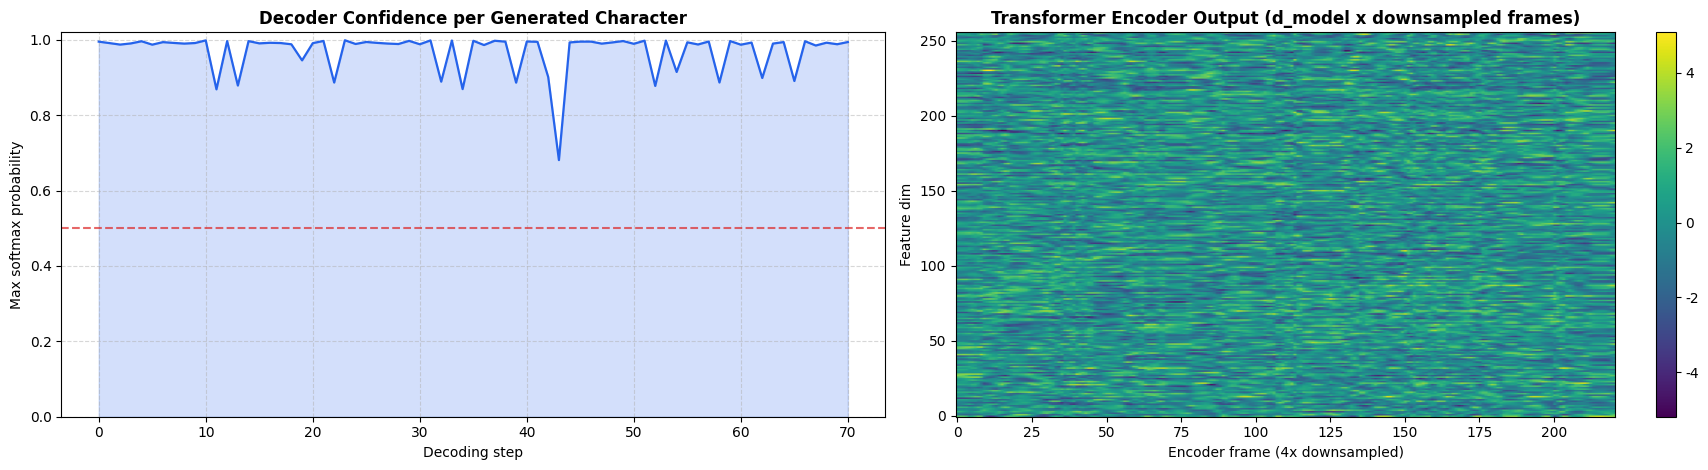

In [18]:
@torch.no_grad()
def transcribe_with_confidence(
    audio_array,
    max_len=300,
    repetition_penalty=1.45,
    no_repeat_ngram_size=4,
):
    """Greedy decode one clip under FP16 autocast, returning text + per-character softmax confidence.
    Equipped with hard n-gram repetition blocking and tighter physical speech length limits."""
    model.eval()
    with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
        mel = extract_log_mel(audio_array, augment=False).unsqueeze(0).to(device)
        lens = torch.tensor([mel.size(1)], device=device)
        memory, mem_mask = model.encode_audio(mel, lens)
        enc_lens = model._compute_cnn_lengths(lens)
        # Strict physical recitation limit (~9.5 chars/sec max)
        dyn_limit = min(max_len, int(enc_lens.item() * 0.38) + 12)

        gen = torch.full((1, 1), tokenizer.sos_id, dtype=torch.long, device=device)
        confs = []
        for _ in range(dyn_limit):
            mask = nn.Transformer.generate_square_subsequent_mask(gen.size(1), device=device)
            emb = model.pos_decoder(model.token_embedding(gen) * math.sqrt(model.d_model))
            out = model.transformer_decoder(tgt=emb, memory=memory, tgt_mask=mask, memory_key_padding_mask=mem_mask)
            logits = model.output_head(out[:, -1, :])

            # 1. Hard n-gram repetition blocking (prevents repeating character 4-grams)
            if no_repeat_ngram_size > 0 and gen.size(1) >= no_repeat_ngram_size:
                seq = gen[0].tolist()
                prefix = tuple(seq[-(no_repeat_ngram_size - 1) :])
                for i in range(len(seq) - no_repeat_ngram_size + 1):
                    if tuple(seq[i : i + no_repeat_ngram_size - 1]) == prefix:
                        banned_tok = seq[i + no_repeat_ngram_size - 1]
                        if banned_tok not in (tokenizer.sos_id, tokenizer.eos_id, tokenizer.pad_id):
                            logits[0, banned_tok] = -float("inf")

            # 2. Soft repetition penalty on recently generated characters (window of 5)
            if repetition_penalty > 1.0 and gen.size(1) > 1:
                recent = set(gen[0, max(1, gen.size(1) - 5) :].tolist())
                for tok in recent:
                    if tok not in (tokenizer.eos_id, tokenizer.pad_id):
                        if logits[0, tok] > 0:
                            logits[0, tok] /= repetition_penalty
                        else:
                            logits[0, tok] *= repetition_penalty

            probs = F.softmax(logits, dim=-1)
            conf, nxt = probs.max(dim=-1)
            gen = torch.cat([gen, nxt.unsqueeze(1)], dim=1)
            confs.append(conf.item())
            if nxt.item() == tokenizer.eos_id:
                break
    return tokenizer.decode(gen[0, 1:]), confs, memory.squeeze(0).cpu()

test_sample = test_audio[min(2, len(test_audio) - 1)]
pred_text, confs, enc_out = transcribe_with_confidence(np.asarray(test_sample["audio"]["array"], dtype=np.float32))
ref_text = preprocess_quran_text(test_sample["ayah_ar"])
print("Reference:", ref_text)
print("Predicted:", pred_text)
print(f"Mean char confidence: {np.mean(confs):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(18, 4.8))
axes[0].plot(confs, color="#2563eb", linewidth=1.6)
axes[0].fill_between(range(len(confs)), confs, alpha=0.2, color="#2563eb")
axes[0].axhline(0.5, color="#dc2626", linestyle="--", alpha=0.7)
axes[0].set_ylim(0, 1.02)
axes[0].set_title("Decoder Confidence per Generated Character", fontweight="bold")
axes[0].set_xlabel("Decoding step"); axes[0].set_ylabel("Max softmax probability")
axes[0].grid(True, linestyle="--", alpha=0.5)

im = axes[1].imshow(enc_out.T.numpy(), aspect="auto", origin="lower", cmap="viridis")
axes[1].set_title("Transformer Encoder Output (d_model x downsampled frames)", fontweight="bold")
axes[1].set_xlabel("Encoder frame (4x downsampled)"); axes[1].set_ylabel("Feature dim")
fig.colorbar(im, ax=axes[1])
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "inference_diagnostics.png"), dpi=150, bbox_inches="tight")
plt.show()

## Step 13 — Full Surah Transcription for One Unseen Reciter (Verse-by-Verse)

Filter:   0%|          | 0/99 [00:00<?, ? examples/s]

Reciter: alafasy | 33 verses
[1] الَّذِينَ كَفَرُوا وَصَدُّوا عَن سَبِيلِ اللَّهِ أَضَلَّ أَعْمَالَهُمْ
[2] وَالَّذِينَ آمَنُوا وَعَمِلُوالصَّا الِحَاتِ وَآمَأَنُزِمَا ا اُزِّلَ عَلَىٰ مُحَّدٍ الْحَقُّ مَقُوَّ رَّبِّهِمْ ۙ كَفَّرَ عْهُمْ سَاتٍ بَهُم
[3] ذَٰلِكَ بِأَنَّ الَّذِينَ كَفَرُوا اتَّبَعُواطِلْبَ وَأَنٰلَّ آمَنُواتَعُزِلْحَ الْحتَقَّ مِن رَّبِّهِمْ ۚ كَذَٰئَٰلبُ يَضْرِلَّهُ لِلنَّاسِ أَمْثَالَهُمْ
[5] سَيَهْدِيهِمْ وَيُصْلِحُ بَالَهُمْ
[6] وَيُدْخِلُهُمُ الْجَنَّةَ عَرَّفَهَا لَهُمْ
[7] يَا أَيُّهَا الَّذِينَ آمَنُوا إِن تَنصُرُواِنصُواقْكُمْ أَقْدَامْ
[8] وَالَّذِينَ كَفَرُوا فَتَعْسًا لَّهُمْ وَأَضَلَّ أَعْمَالكُمْ
[9] ذَٰلِكَ بِأَنَّهُمْ كَرِهُوا مَا أَنزَلَ اللَّهشَ فَأَحْبَطَ أَعْمَالَهُمكَهُُمْ
[10] أَفَلَمْ يَسِيرُوا فِي الْأَرْضِ فَيَنظُرُوءَيْفَ كَنَانَ عَاقِبَةُ الَّذِينَ مِن قَبْلِهِمْ ۚ دَمَّرَ اللَّهُ عَلَيْهِم
[11] ذَٰلِكَ بِأَنَّ اللَّهَ مَوْلَى الَّذِينَ آمَنُوا وَأَنكَّ آموَّ جَنَهُمْكَافِرِينظَ لَا مَىٰ لَهُْ
[12] إِنَّ اللَّهَ يُدْخِلُ الَّذِينَ آمَنُوا وَعَم

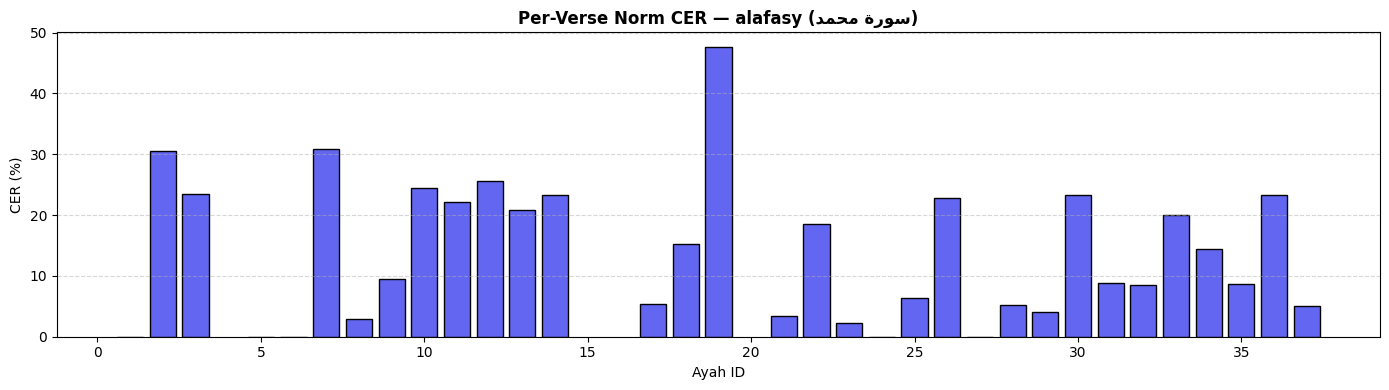

All plots saved to: /content/drive/MyDrive/quran-hybrid-asr-muhammad/visualizations


In [19]:
target_reciter = sorted(test_reciters)[0]
subset = test_audio.filter(lambda x: x[reciter_col] == target_reciter).sort("ayah_id")
print(f"Reciter: {target_reciter} | {len(subset)} verses\n" + "=" * 60)
cers = []
for row in subset:
    p, _, _ = transcribe_with_confidence(np.asarray(row["audio"]["array"], dtype=np.float32), max_len=300)
    r = normalize_arabic(preprocess_quran_text(row["ayah_ar"]))
    cers.append(100 * jiwer.cer(r, normalize_arabic(p)) if r and p else 100.0)
    print(f"[{row['ayah_id']}] {p}")
print("=" * 60)

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(subset["ayah_id"], cers, color="#6366f1", edgecolor="black")
ax.set_title(f"Per-Verse Norm CER — {target_reciter} ({shape_ar(SURAH_NAME_AR)})", fontweight="bold")
ax.set_xlabel("Ayah ID"); ax.set_ylabel("CER (%)"); ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "full_surah_reciter_cer.png"), dpi=150, bbox_inches="tight")
plt.show()
print("All plots saved to:", PLOTS_DIR)

## Step 14 — Transcribe Full Surah Audio Verse-by-Verse for Al-Husary

In [20]:
husary_ds = raw_dataset.cast_column("audio", Audio(decode=False))
husary_ds = husary_ds.filter(lambda x: x[reciter_col] == "husary").sort("ayah_id")

# Check reciter split to ensure transparent evaluation (seen vs unseen voice)
husary_split = "Train (Seen voice)" if "husary" in train_reciters else ("Validation" if "husary" in eval_reciters else "Test (Held-Out / Unseen voice)")

model.eval()
print(f"\nTranscribed Recitation ({SURAH_NAME_AR} - محمود خليل الحصري):")
print(f"Split Verification: 'husary' belongs to [{husary_split}]")
if "Train" in husary_split:
    print("  -> Acoustic Fitting / Memorization Benchmark on Seen Reciter Voice.")
else:
    print("  -> Generalization Benchmark on Unseen Reciter Voice.")
print("=" * 60)

for row in husary_ds:
    audio_dict = row["audio"]
    if audio_dict and "bytes" in audio_dict:
        try:
            with io.BytesIO(audio_dict["bytes"]) as f:
                waveform, sample_rate = torchaudio.load(f)

            if waveform.size(0) > 1:
                waveform = waveform.mean(dim=0, keepdim=True)

            if sample_rate != 16000:
                resampler = T.Resample(orig_freq=sample_rate, new_freq=16000)
                waveform = resampler(waveform)

            array = waveform.squeeze(0).numpy()
            mel_tensor = extract_log_mel(array, sr=16000, n_mels=80, augment=False).unsqueeze(0).to(device)
            mel_lens = torch.tensor([mel_tensor.size(1)], dtype=torch.long, device=device)

            with torch.no_grad():
                gen_ids = model.greedy_decode(
                    mel_tensor,
                    mel_lens,
                    sos_id=tokenizer.sos_id,
                    eos_id=tokenizer.eos_id,
                    max_len=300,
                )

            prediction = tokenizer.decode(gen_ids[0].cpu().tolist())
            print(f"[{row['ayah_id']}] {prediction}")

        except Exception as e:
            print(f"[Error in Ayah {row['ayah_id']}] {e}")

print("=" * 60)
print("Al-Husary Transcription Complete.")

Filter:   0%|          | 0/1140 [00:00<?, ? examples/s]


Transcribed Recitation (سورة محمد - محمود خليل الحصري):
Split Verification: 'husary' belongs to [Validation]
  -> Generalization Benchmark on Unseen Reciter Voice.
[1] الَّذِينَ كَفَرُوا وَصَدُّوا عَن سَبِيلِ اللَّهِ أَضَلَّ أَعْمَالَهُمْ
[2] وَالَّذِينَ آمَنُوا وَعَمِلُوالصَّا الِحَاتِ وَآمَأَنُزِّلَ ا عَلَىٰ مُحَّدٍ الْحَقُّ مَّبِن رَّهِمْ ۙ كَفَّرَ عَنْهُمْ سَيِّئَاتْلَحَهُم
[3] ذَٰلِكَ بِأَنَّ الَّذِينَ كَفَرُوا اتَّبَعُواطِلَ واطلَأَنُواسُوامِلَّ واتَعُزِلْحَقَّ مِنُوبَّ رَّهِمْ ۚ كَذَٰئَرِكَاتَ الِكنُ بُوالِلَْ أَمَنَضْثَالَهُمْ
[4] أَفَهَلْ يَسِيرُونَّي الْتَ الَّذِين كَرَهُ أَمَن لْتِيَ آمَضْرَ ذَكْ
[5] سَيَهْدِيهِمْ وَيُصْلِحُ بَالَهُمْ
[6] وَيُدْخِلُهُمُ الْجَنَّةَ عَرَّفَهَا لَهُمْ
[7] يَا أَيُّهَا الَّذِينَ آمَنُوا إِن تَنصُرُواِنصُواقْكُمْ أَقْدَامْ
[8] وَالَّذِينَ كَفَرُوا فَتَعْسًا لَّهُمْ وَأَضَلَّ أَعْمَالنَهُم
[9] ذَٰلِكَ بِأَنَّهُمْ كَرِهُوا مَا أَنزَلَ اللَّهشَ فَأَحْبَطَ أَعْمَالَهُمًالَوْ
[10] أَفَلَمْ يَسِيرُوا فِي الْأَرْضِ فَيَنظُرُوءَيْفَ كَنَ عَاقِبَةُ الَّذ

## Step 15 — Transcribe Full Surah Audio Verse-by-Verse for Muhammad Jibreel

In [21]:
jibreel_ds = raw_dataset.cast_column("audio", Audio(decode=False))
jibreel_ds = jibreel_ds.filter(lambda x: x[reciter_col] == "muhammad_jibreel").sort("ayah_id")

# Check reciter split to ensure transparent evaluation (seen vs unseen voice)
jibreel_split = "Train (Seen voice)" if "muhammad_jibreel" in train_reciters else ("Validation" if "muhammad_jibreel" in eval_reciters else "Test (Held-Out / Unseen voice)")

model.eval()
print(f"\nTranscribed Recitation ({SURAH_NAME_AR} - محمد جبريل):")
print(f"Split Verification: 'muhammad_jibreel' belongs to [{jibreel_split}]")
if "Train" in jibreel_split:
    print("  -> Acoustic Fitting / Memorization Benchmark on Seen Reciter Voice.")
else:
    print("  -> Generalization Benchmark on Unseen Reciter Voice.")
print("=" * 60)

for row in jibreel_ds:
    audio_dict = row["audio"]
    if audio_dict and "bytes" in audio_dict:
        try:
            with io.BytesIO(audio_dict["bytes"]) as f:
                waveform, sample_rate = torchaudio.load(f)

            if waveform.size(0) > 1:
                waveform = waveform.mean(dim=0, keepdim=True)

            if sample_rate != 16000:
                resampler = T.Resample(orig_freq=sample_rate, new_freq=16000)
                waveform = resampler(waveform)

            array = waveform.squeeze(0).numpy()
            mel_tensor = extract_log_mel(array, sr=16000, n_mels=80, augment=False).unsqueeze(0).to(device)
            mel_lens = torch.tensor([mel_tensor.size(1)], dtype=torch.long, device=device)

            with torch.no_grad():
                gen_ids = model.greedy_decode(
                    mel_tensor,
                    mel_lens,
                    sos_id=tokenizer.sos_id,
                    eos_id=tokenizer.eos_id,
                    max_len=300,
                )

            prediction = tokenizer.decode(gen_ids[0].cpu().tolist())
            print(f"[{row['ayah_id']}] {prediction}")

        except Exception as e:
            print(f"[Error in Ayah {row['ayah_id']}] {e}")

print("=" * 60)
print("Muhammad Jibreel Transcription Complete.")

Filter:   0%|          | 0/1140 [00:00<?, ? examples/s]


Transcribed Recitation (سورة محمد - محمد جبريل):
Split Verification: 'muhammad_jibreel' belongs to [Test (Held-Out / Unseen voice)]
  -> Generalization Benchmark on Unseen Reciter Voice.
[1] الَّذِينَ كَفَرُوا وَصَدُّوا عَن سَبِيلِ اللَّهِ أَضَلَّ أَعْمَالَهُمْ
[2] وَالَّذِينَ آمَنُوا وَعَمِلُواحَّا الصَاتِ وَآمَأَنُزِّلَ ا ارَلَّدٍ وَهُون آمِّبَ ن ۙ كَلَهُمْ كَصْحَاتٍ رَّبِهُميَ ۙ فَّرَ يَهُلْ بَالنَهُْ
[3] ذَٰلِكَ بِأَنَّ الَّذِينَ كَفَرُوا اتَّبَعُواطِلْبَ وَأَنٍ الْبوَّذٰلَ اتأَّذبَ النَّذالْحَ مَن الِين اتٍكَّبِن ا رَّهِمْ ۚ كَذََٰضْرِبُ اللَّهُ لِلنَمْ
[4] أَفَاعَمَنَّذِينَ الَّهُ الِيَ سُوَأَمَّن الرَّهِ يَ ا أَملَنظُ احْ
[5] سَيَهْدِيهِمْ وَيُصْلِحُ بَالَهُمْ
[6] وَيُدْخِلُهُمُ الْجَنَّةَ عَرَّفَهَا لَهُمْ
[7] يَا أَيُّهَا الَّذِينَ آمَنُوا إِن تَنصُرُواِنصُواقْكُمْ أَدَامْ اللَكُمّهَبِ وَقْ
[8] وَالَّذِينَ كَفَرُوا فَتَعْسًا لَّهُمْ وَأَضَلَّ أَعْمَال
[9] ذَٰلِكَ بِأَنَّهُمْ كَرِهُوا مَا أَنزَلَ اللَّهشَ فَأَحْبَطَ أَعْمَالَهُمًالَِسْ
[10] أَفَلَمْ يَسِيرُوا فِي الْأَرْضِ فَي